# Combined MS1 — data cleaning and auditing

Preserves shared work and the four member sections. Missing-value filling remains deferred. Flagged anomalies remain unresolved unless explicitly documented. Original CSVs and input notebooks are unchanged. See `acl-ms1-merge-notes.md` for integration changes.


In [148]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Kaggle first; local archive is supported for verification.
DATA_DIR = Path("/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020")
if not DATA_DIR.exists():
    DATA_DIR = Path("archive")
if not DATA_DIR.exists():
    raise FileNotFoundError("Set DATA_DIR to the folder containing the F1 CSV files.")


In [149]:
circuits =  pd.read_csv(DATA_DIR / "circuits.csv") 
constructor_results =  pd.read_csv(DATA_DIR / "constructor_results.csv") 
constructor_standings =  pd.read_csv(DATA_DIR / "constructor_standings.csv") 
constructors =  pd.read_csv(DATA_DIR / "constructors.csv") 
driver_standings =  pd.read_csv(DATA_DIR / "driver_standings.csv") 
drivers =  pd.read_csv(DATA_DIR / "drivers.csv") 
lap_times =  pd.read_csv(DATA_DIR / "lap_times.csv") 
pit_stops =  pd.read_csv(DATA_DIR / "pit_stops.csv") 
qualifying =  pd.read_csv(DATA_DIR / "qualifying.csv") 
races =  pd.read_csv(DATA_DIR / "races.csv") 
seasons =  pd.read_csv(DATA_DIR / "seasons.csv") 
sprint_results =  pd.read_csv(DATA_DIR / "sprint_results.csv") 
status =  pd.read_csv(DATA_DIR / "status.csv") 
results =  pd.read_csv(DATA_DIR / "results.csv") 

## Shared section — circuits and constructor results


## circuits.csv

One row identifies one circuit. `circuitId` is its primary key. There are no date, duration, or foreign-key columns.


In [150]:

circuits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


,Data type,Recognized missing,Placeholders
circuitId,int64,0,0
circuitRef,object,0,0
name,object,0,0
location,object,0,0
country,object,0,0
lat,float64,0,0
lng,float64,0,0
alt,int64,0,0
url,object,0,0


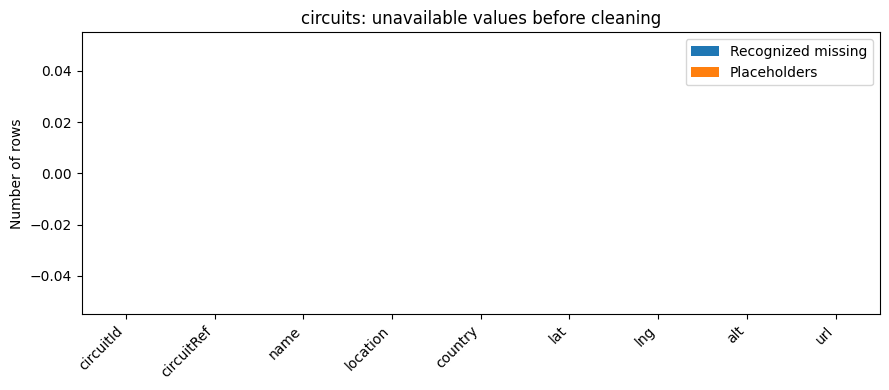

In [151]:
# Count recognized missing values and literal placeholders separately.
circuits_before_summary = pd.DataFrame({
    "Data type": circuits.dtypes.astype(str),
    "Recognized missing": circuits.isna().sum(),
    "Placeholders": circuits.eq(r"\N").sum()
})
display(circuits_before_summary)
circuits_before_summary[["Recognized missing", "Placeholders"]].plot.bar(figsize=(9, 4))
plt.title("circuits: unavailable values before cleaning")
plt.ylabel("Number of rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


The original `info()` output checks recognized missing values only. Literal `\N` placeholders require a separate check; no placeholders were found in the inspected circuits copy.


In [152]:
# Display every row and column.
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(circuits)

,circuitId,circuitRef,name,location,country,lat,lng,alt,url
0,1,albert_park,Albert Park Grand Prix Circuit,Melbourne,Australia,-37.84970,144.968000,10,http://en.wikipedia.org/wiki/Melbourne_Grand_P...
1,2,sepang,Sepang International Circuit,Kuala Lumpur,Malaysia,2.76083,101.738000,18,http://en.wikipedia.org/wiki/Sepang_Internatio...
2,3,bahrain,Bahrain International Circuit,Sakhir,Bahrain,26.03250,50.510600,7,http://en.wikipedia.org/wiki/Bahrain_Internati...
3,4,catalunya,Circuit de Barcelona-Catalunya,Montmeló,Spain,41.57000,2.261110,109,http://en.wikipedia.org/wiki/Circuit_de_Barcel...
4,5,istanbul,Istanbul Park,Istanbul,Turkey,40.95170,29.405000,130,http://en.wikipedia.org/wiki/Istanbul_Park
5,6,monaco,Circuit de Monaco,Monte-Carlo,Monaco,43.73470,7.420560,7,http://en.wikipedia.org/wiki/Circuit_de_Monaco
6,7,villeneuve,Circuit Gilles Villeneuve,Montreal,Canada,45.50000,-73.522800,13,http://en.wikipedia.org/wiki/Circuit_Gilles_Vi...
7,8,magny_cours,Circuit de Nevers Magny-Cours,Magny Cours,France,46.86420,3.163610,228,http://en.wikipedia.org/wiki/Circuit_de_Nevers...
8,9,silverstone,Silverstone Circuit,Silverstone,UK,52.07860,-1.016940,153,http://en.wikipedia.org/wiki/Silverstone_Circuit
9,10,hockenheimring,Hockenheimring,Hockenheim,Germany,49.32780,8.565830,103,http://en.wikipedia.org/wiki/Hockenheimring


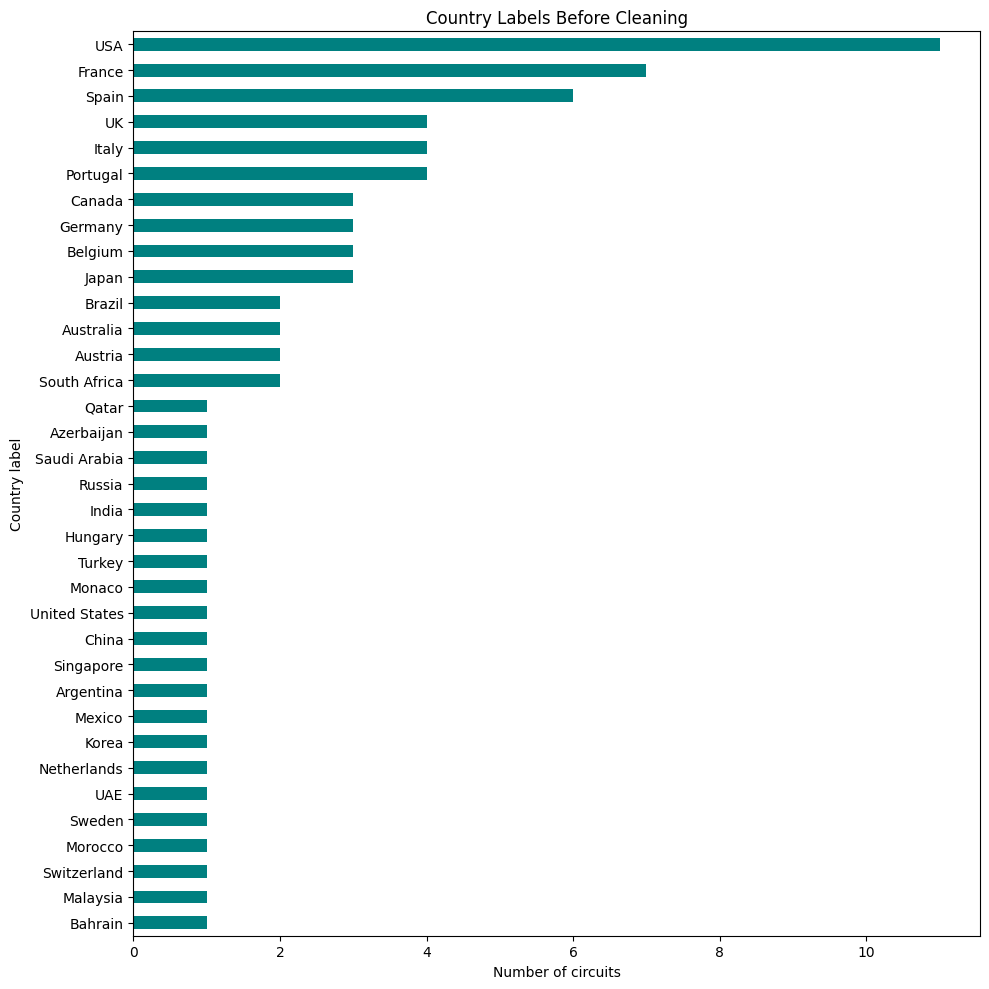

In [153]:

counts = circuits["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels Before Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [154]:
circuits_clean = circuits.copy(deep=True).replace(r"\N", np.nan)
for column in circuits_clean.select_dtypes(include="object").columns:
    circuits_clean[column] = circuits_clean[column].str.strip()
circuits_clean["country"] = circuits_clean["country"].replace({"USA": "United States"})
for column in ["lat", "lng", "alt"]:
    circuits_clean[column] = pd.to_numeric(circuits_clean[column], errors="raise")


,Placeholders BEFORE,Placeholders AFTER,Recognized missing BEFORE,Recognized missing AFTER
circuitId,0,0,0,0
circuitRef,0,0,0,0
name,0,0,0,0
location,0,0,0,0
country,0,0,0,0
lat,0,0,0,0
lng,0,0,0,0
alt,0,0,0,0
url,0,0,0,0


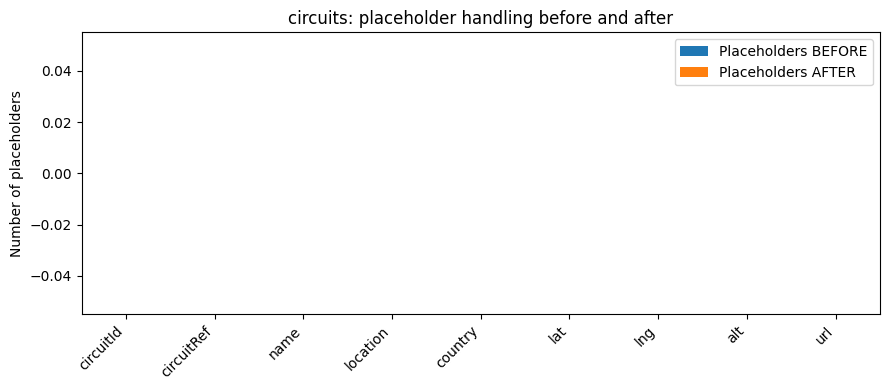

In [155]:
circuits_comparison = pd.DataFrame({
    "Placeholders BEFORE": circuits.eq(r"\N").sum(),
    "Placeholders AFTER": circuits_clean.eq(r"\N").sum(),
    "Recognized missing BEFORE": circuits.isna().sum(),
    "Recognized missing AFTER": circuits_clean.isna().sum()
})
display(circuits_comparison)
circuits_comparison[["Placeholders BEFORE", "Placeholders AFTER"]].plot.bar(figsize=(9, 4))
plt.title("circuits: placeholder handling before and after")
plt.ylabel("Number of placeholders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Recognized missing counts can rise when placeholders are converted. This does not mean new information was lost. Zero placeholder counts before and after indicate that no replacement was needed in those columns.


In [156]:
changed_countries = circuits["country"].fillna("<MISSING>").ne(circuits_clean["country"].fillna("<MISSING>"))
display(pd.DataFrame({
    "country BEFORE": circuits.loc[changed_countries, "country"],
    "country AFTER": circuits_clean.loc[changed_countries, "country"]
}))
print("Country labels changed:", changed_countries.sum())


,country BEFORE,country AFTER
18,USA,United States
32,USA,United States
36,USA,United States
41,USA,United States
42,USA,United States
43,USA,United States
45,USA,United States
59,USA,United States
62,USA,United States
68,USA,United States


Country labels changed: 11


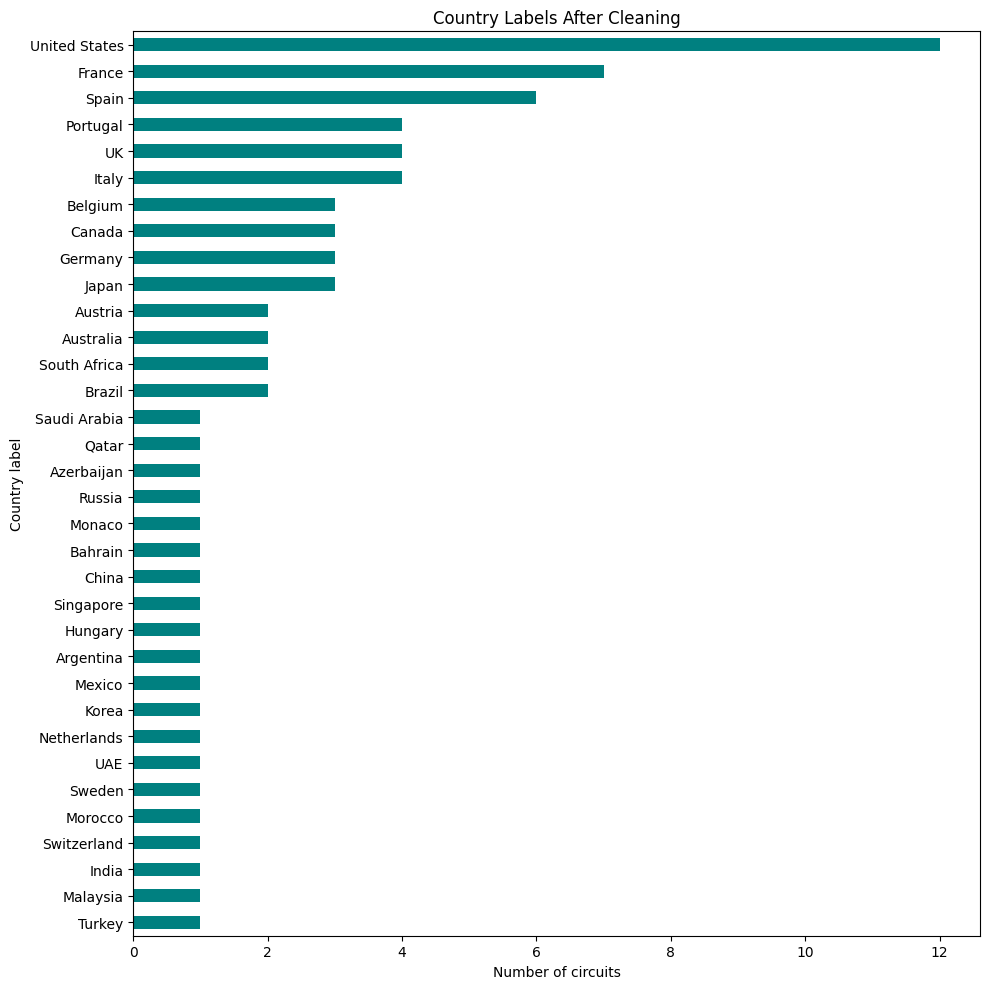

In [157]:

counts = circuits_clean["country"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))

counts.plot.barh(ax=ax, color="teal")

ax.set_title("Country Labels After Cleaning")
ax.set_xlabel("Number of circuits")
ax.set_ylabel("Country label")

plt.tight_layout()
plt.show()

In [158]:
print("Missing circuit IDs:",
      circuits_clean["circuitId"].isna().sum())

print("Duplicate circuit IDs:",
      circuits_clean["circuitId"].duplicated().sum())

assert circuits_clean["circuitId"].notna().all(), "Missing circuit IDs found"
assert circuits_clean["circuitId"].is_unique, "Duplicate circuit IDs found"

print("Passed: circuitId is unique and non-null.")

Missing circuit IDs: 0
Duplicate circuit IDs: 0
Passed: circuitId is unique and non-null.


### Circuits: reason for country-label standardization

We followed the reference URLs stored in `circuits.url` to check the country of the actual circuits.

| Circuit record | Original `country` | Country identified by its reference |
|---|---|---|
| Circuit of the Americas (`circuitId = 69`) | `USA` | United States — the reference gives its location as Austin, Texas, United States |
| Las Vegas Strip Street Circuit (`circuitId = 80`) | `United States` | United States — the reference identifies the event as taking place in Nevada, United States |

Sources supplied in the CSV: [Circuit of the Americas](https://en.wikipedia.org/wiki/Circuit_of_the_Americas) and [Las Vegas Grand Prix](https://en.wikipedia.org/wiki/Las_Vegas_Grand_Prix#Circuit).

The common country identified by these references supports treating `USA` and `United States` as equivalent labels. We standardize to `United States` so country-level grouping does not split the same country. This is label standardization: the circuits remain different records with their original circuit IDs. Neither original country label is wrong. There is no shared country ID in the CSVs; the evidence comes from the referenced pages, not from a join or before/after counts.

The older `Las Vegas Street Circuit` URL now redirects to the modern Strip circuit, so that redirect is not used as evidence that the historical and modern circuits are identical.

No missing values are filled. Negative coordinates or altitude are not automatically errors. Coordinate-range checks test valid geographic limits, not precise location accuracy. Raw CSVs remain unchanged.


In [159]:
circuits_checks = pd.Series({
    "Rows unchanged": len(circuits_clean) == len(circuits),
    "Columns unchanged": circuits_clean.columns.equals(circuits.columns),
    "No placeholders remain": not circuits_clean.eq(r"\N").any().any(),
    "No duplicate rows": not circuits_clean.duplicated().any(),
    "circuitId non-null": circuits_clean["circuitId"].notna().all(),
    "circuitId unique": circuits_clean["circuitId"].is_unique,
    "Latitude within bounds": circuits_clean["lat"].dropna().between(-90, 90).all(),
    "Longitude within bounds": circuits_clean["lng"].dropna().between(-180, 180).all()
})
display(circuits_checks.to_frame("Passed"))
assert circuits_checks.all(), "Investigate failed circuits checks."
circuits_clean.info()


,Passed
Rows unchanged,True
Columns unchanged,True
No placeholders remain,True
No duplicate rows,True
circuitId non-null,True
circuitId unique,True
Latitude within bounds,True
Longitude within bounds,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


## constructor_results.csv

One row records a constructor result for a race. The primary key is `constructorResultsId`; `(raceId, constructorId)` should also be unique. No date or duration conversion applies. Current-race points are not pre-race model inputs.


In [160]:
constructor_results.head()

,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,\N
1,2,18,2,8.0,\N
2,3,18,3,9.0,\N
3,4,18,4,5.0,\N
4,5,18,5,2.0,\N


,Data type,Recognized missing,Placeholders
constructorResultsId,int64,0,0
raceId,int64,0,0
constructorId,int64,0,0
points,float64,0,0
status,object,0,12608


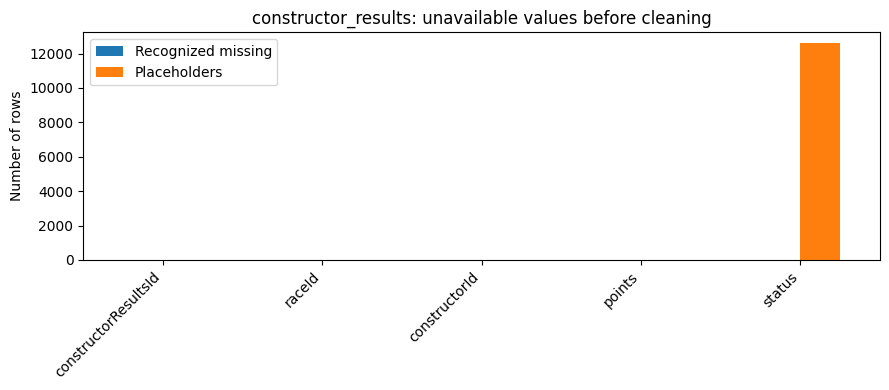

In [161]:
# Count recognized missing values and literal placeholders separately.
constructor_results_before_summary = pd.DataFrame({
    "Data type": constructor_results.dtypes.astype(str),
    "Recognized missing": constructor_results.isna().sum(),
    "Placeholders": constructor_results.eq(r"\N").sum()
})
display(constructor_results_before_summary)
constructor_results_before_summary[["Recognized missing", "Placeholders"]].plot.bar(figsize=(9, 4))
plt.title("constructor_results: unavailable values before cleaning")
plt.ylabel("Number of rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [162]:
constructor_results_clean = constructor_results.copy(deep=True)
constructor_results_clean = constructor_results_clean.replace(r"\N", np.nan)
constructor_results_clean["points"] = pd.to_numeric(constructor_results_clean["points"], errors="raise")
display(constructor_results_clean.head())


,constructorResultsId,raceId,constructorId,points,status
0,1,18,1,14.0,NaN
1,2,18,2,8.0,NaN
2,3,18,3,9.0,NaN
3,4,18,4,5.0,NaN
4,5,18,5,2.0,NaN


In [163]:
constructor_results_clean.isnull().sum()

constructorResultsId        0
raceId                      0
constructorId               0
points                      0
status                  12608
dtype: int64

,Placeholders BEFORE,Placeholders AFTER,Recognized missing BEFORE,Recognized missing AFTER
constructorResultsId,0,0,0,0
raceId,0,0,0,0
constructorId,0,0,0,0
points,0,0,0,0
status,12608,0,0,12608


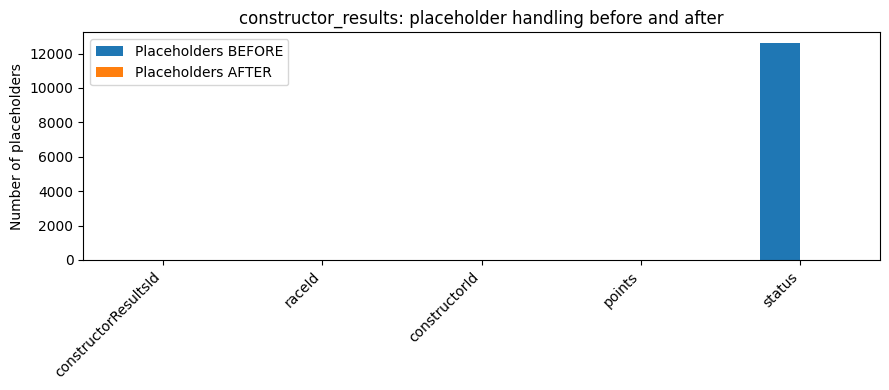

In [164]:
constructor_results_comparison = pd.DataFrame({
    "Placeholders BEFORE": constructor_results.eq(r"\N").sum(),
    "Placeholders AFTER": constructor_results_clean.eq(r"\N").sum(),
    "Recognized missing BEFORE": constructor_results.isna().sum(),
    "Recognized missing AFTER": constructor_results_clean.isna().sum()
})
display(constructor_results_comparison)
constructor_results_comparison[["Placeholders BEFORE", "Placeholders AFTER"]].plot.bar(figsize=(9, 4))
plt.title("constructor_results: placeholder handling before and after")
plt.ylabel("Number of placeholders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Recognized missing counts can rise when placeholders are converted. This does not mean new information was lost. Zero placeholder counts before and after indicate that no replacement was needed in those columns.


In [165]:


display(
    constructor_results_clean["status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Number of rows")
)

# Display the special flagged records.
display(
    constructor_results_clean.loc[
        constructor_results_clean["status"].notna()
    ]
)

,Status,Number of rows
0,NaN,12608
1,D,17


,constructorResultsId,raceId,constructorId,points,status
185,186,36,1,14.0,D
195,196,37,1,18.0,D
207,208,38,1,12.0,D
218,219,39,1,14.0,D
228,229,40,1,18.0,D
239,240,41,1,12.0,D
250,251,42,1,18.0,D
262,263,43,1,8.0,D
273,274,44,1,14.0,D
283,284,45,1,10.0,D


In [166]:
# Check the record ID.
record_id = "constructorResultsId"

print("Missing constructorResultsId:",
      constructor_results_clean[record_id].isna().sum())

print("Duplicate constructorResultsId:",
      constructor_results_clean[record_id].duplicated().sum())

assert constructor_results_clean[record_id].notna().all(), \
    "Missing constructorResultsId found"

assert constructor_results_clean[record_id].is_unique, \
    "Duplicate constructorResultsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_results_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_results_clean.duplicated(pair_columns).sum())

assert constructor_results_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_results_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorResultsId: 0
Duplicate constructorResultsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [167]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_results_clean[
    constructor_results_clean["raceId"].isna()
    | ~constructor_results_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_results_clean[
    constructor_results_clean["constructorId"].isna()
    | ~constructor_results_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


### Constructor results: final checks and findings

Literal `\N` entries are converted to recognized missing values without filling them. `status` is a special constructor-result flag, not the driver retirement reason from `status.csv`. Missing status entries and the `D` flag are preserved; their meaning must be verified before analytical use. The key and reference checks above validate identifiers, not the interpretation of that flag.


In [168]:
constructor_results_checks = pd.Series({
    "Rows unchanged": len(constructor_results_clean) == len(constructor_results),
    "Columns unchanged": constructor_results_clean.columns.equals(constructor_results.columns),
    "No placeholders remain": not constructor_results_clean.eq(r"\N").any().any(),
    "No duplicate rows": not constructor_results_clean.duplicated().any(),
    "Points are numeric": pd.api.types.is_numeric_dtype(constructor_results_clean["points"]),
    "Points non-negative": constructor_results_clean["points"].dropna().ge(0).all()
})
display(constructor_results_checks.to_frame("Passed"))
assert constructor_results_checks.all(), "Investigate failed constructor-result checks."
constructor_results_clean.info()


,Passed
Rows unchanged,True
Columns unchanged,True
No placeholders remain,True
No duplicate rows,True
Points are numeric,True
Points non-negative,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12625 entries, 0 to 12624
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   constructorResultsId  12625 non-null  int64  
 1   raceId                12625 non-null  int64  
 2   constructorId         12625 non-null  int64  
 3   points                12625 non-null  float64
 4   status                17 non-null     object 
dtypes: float64(1), int64(3), object(1)
memory usage: 493.3+ KB


# Rezk — Data cleaning and auditing

Scope: drivers, lap times, and pit stops. Original tables remain unchanged; cleaning uses copies. Missing-value filling is deferred. Suspected recording issues are flagged rather than corrected without verification.


# 1. drivers.csv

### Before-cleaning inspection

Each row represents one driver. `driverId` is the primary key.


In [179]:
print("Rows:", len(drivers))
print("Columns:", len(drivers.columns))
display(drivers.head(10))
drivers.info()


Rows: 861
Columns: 9


,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
5,6,nakajima,\N,NAK,Kazuki,Nakajima,1985-01-11,Japanese,http://en.wikipedia.org/wiki/Kazuki_Nakajima
6,7,bourdais,\N,BOU,Sébastien,Bourdais,1979-02-28,French,http://en.wikipedia.org/wiki/S%C3%A9bastien_Bo...
7,8,raikkonen,7,RAI,Kimi,Räikkönen,1979-10-17,Finnish,http://en.wikipedia.org/wiki/Kimi_R%C3%A4ikk%C...
8,9,kubica,88,KUB,Robert,Kubica,1984-12-07,Polish,http://en.wikipedia.org/wiki/Robert_Kubica
9,10,glock,\N,GLO,Timo,Glock,1982-03-18,German,http://en.wikipedia.org/wiki/Timo_Glock


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   driverId     861 non-null    int64 
 1   driverRef    861 non-null    object
 2   number       861 non-null    object
 3   code         861 non-null    object
 4   forename     861 non-null    object
 5   surname      861 non-null    object
 6   dob          861 non-null    object
 7   nationality  861 non-null    object
 8   url          861 non-null    object
dtypes: int64(1), object(8)
memory usage: 60.7+ KB


### Placeholder handling and before/after evidence


In [180]:
sentinels_before = drivers.eq(r"\N").sum()

display(
    sentinels_before.to_frame("Missing placeholders BEFORE")
)

,Missing placeholders BEFORE
driverId,0
driverRef,0
number,802
code,757
forename,0
surname,0
dob,0
nationality,0
url,0


In [181]:

drivers_clean = drivers.copy(deep=True)
drivers_clean = drivers_clean.replace(r"\N", np.nan)

In [182]:
comparison = pd.DataFrame({
    "Placeholders BEFORE": drivers.eq(r"\N").sum(),
    "Placeholders AFTER": drivers_clean.eq(r"\N").sum(),
    "Recognized missing BEFORE": drivers.isna().sum(),
    "Recognized missing AFTER": drivers_clean.isna().sum()
})

display(comparison)

,Placeholders BEFORE,Placeholders AFTER,Recognized missing BEFORE,Recognized missing AFTER
driverId,0,0,0,0
driverRef,0,0,0,0
number,802,0,0,802
code,757,0,0,757
forename,0,0,0,0
surname,0,0,0,0
dob,0,0,0,0
nationality,0,0,0,0
url,0,0,0,0


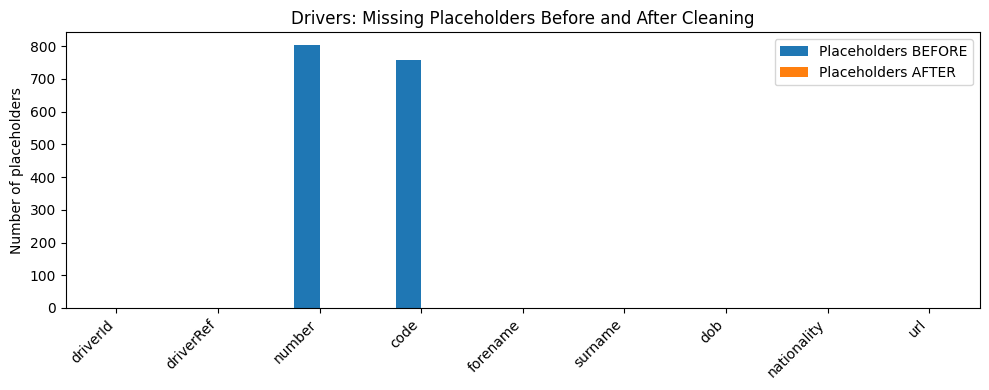

In [183]:
comparison[[
    "Placeholders BEFORE",
    "Placeholders AFTER"
]].plot.bar(figsize=(10, 4))

plt.title("Drivers: Missing Placeholders Before and After Cleaning")
plt.ylabel("Number of placeholders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The original data uses `\N` to represent missing information.
We counted these placeholders before cleaning, then replaced them with
recognized missing values in a copy. The comparison confirms that no `\N`
placeholders remain. Missing information was preserved, not guessed or filled.

### Nationality inspection and correction


In [184]:
# Show every nationality label and its count.
nationality_counts = (
    drivers_clean["nationality"]
    .value_counts(dropna=False)
    .rename_axis("Nationality")
    .reset_index(name="Number of drivers")
)

# Quotes make surrounding spaces visible.
nationality_counts["Nationality"] = (
    nationality_counts["Nationality"].map(repr)
)

with pd.option_context("display.max_rows", None):
    display(nationality_counts)

,Nationality,Number of drivers
0,'British',166
1,'American',158
2,'Italian',99
3,'French',73
4,'German',50
5,'Brazilian',32
6,'Argentine',24
7,'Belgian',23
8,'Swiss',23
9,'South African',23


In [185]:
nationality_before = drivers["nationality"].copy()

# Remove surrounding spaces.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].str.strip()
)

# Use one label for the same nationality.
drivers_clean["nationality"] = (
    drivers_clean["nationality"].replace({
        "Argentinian": "Argentine"
    })
)

In [186]:
changed = (
    nationality_before.fillna("<MISSING>")
    != drivers_clean["nationality"].fillna("<MISSING>")
)

changes = drivers_clean.loc[
    changed, ["driverId", "forename", "surname"]
].copy()

# Quotes make the original trailing spaces visible.
changes["Nationality BEFORE"] = nationality_before.loc[changed].map(repr)
changes["Nationality AFTER"] = (
    drivers_clean.loc[changed, "nationality"].map(repr)
)

display(changes)
print("Rows changed:", changed.sum())

,driverId,forename,surname,Nationality BEFORE,Nationality AFTER
859,861,Franco,Colapinto,'Argentinian ','Argentine'


Rows changed: 1


,Before,After
'Argentine',24,25
'Argentinian',0,0
'Argentinian ',1,0


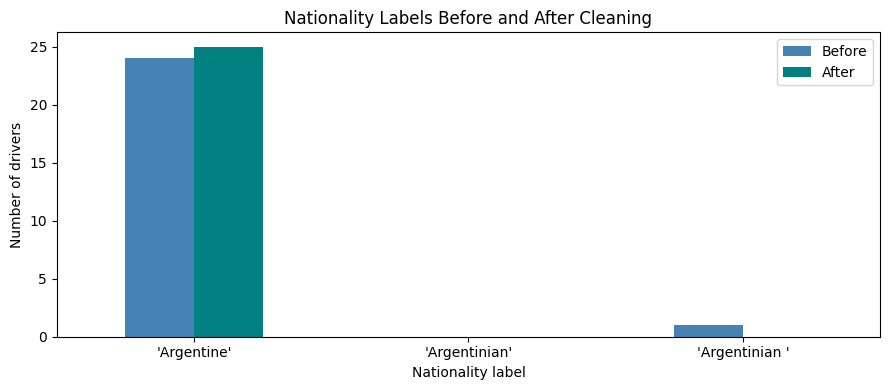

In [187]:
labels = ["Argentine", "Argentinian", "Argentinian "]

nationality_comparison = pd.DataFrame({
    "Before": nationality_before.value_counts().reindex(
        labels, fill_value=0
    ),
    "After": drivers_clean["nationality"].value_counts().reindex(
        labels, fill_value=0
    )
})

nationality_comparison.index = [repr(label) for label in labels]

display(nationality_comparison)

nationality_comparison.plot.bar(
    figsize=(9, 4),
    color=["steelblue", "teal"]
)

plt.title("Nationality Labels Before and After Cleaning")
plt.xlabel("Nationality label")
plt.ylabel("Number of drivers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Reason for nationality-label standardization

We followed the reference URLs stored in `drivers.url` and checked the explicit nationality fields, rather than inferring nationality from birthplace, team, or races entered.

| Driver record | Original `nationality` | Nationality identified by its reference |
|---|---|---|
| Franco Colapinto (`driverId = 861`) | `"Argentinian "` | Argentine |
| Gastón Mazzacane (`driverId = 60`) | `Argentine` | Argentine |

Sources supplied in the CSV: [Franco Colapinto](https://en.wikipedia.org/wiki/Franco_Colapinto) and [Gastón Mazzacane](https://en.wikipedia.org/wiki/Gast%C3%B3n_Mazzacane). Both pages identify the driver's Formula One nationality as Argentine.

Colapinto's own reference supports standardizing his label to the existing `Argentine` category. We also remove the trailing space. This prevents the same nationality being separated into two categories; the before/after counts demonstrate the effect, not the reason for the change. No driver records are merged or removed. `Argentine-Italian` remains separate because replacing it would discard information. No nationality ID or country code was inferred to exist in the original data.


### Birth-date typing and before/after evidence


In [188]:
# Preserve values before this change.
dob_before = drivers["dob"].replace(r"\N", np.nan).copy()

converted_dob = pd.to_datetime(
    dob_before,
    format="%Y-%m-%d",
    errors="coerce"
)

# Find non-missing strings that could not be converted.
invalid_dates = dob_before.notna() & converted_dob.isna()

print("Invalid non-missing birth dates:", invalid_dates.sum())

if invalid_dates.any():
    display(
        drivers_clean.loc[
            invalid_dates,
            ["driverId", "forename", "surname", "dob"]
        ]
    )

assert not invalid_dates.any(), \
    "Investigate invalid birth dates before continuing."

drivers_clean["dob"] = converted_dob

Invalid non-missing birth dates: 0


In [189]:
display(pd.DataFrame({
    "BEFORE": dob_before.head(),
    "AFTER": drivers_clean["dob"].head()
}))

print("Type BEFORE:", dob_before.dtype)
print("Type AFTER:", drivers_clean["dob"].dtype)

print("Missing dates BEFORE:", dob_before.isna().sum())
print("Missing dates AFTER:", drivers_clean["dob"].isna().sum())

,BEFORE,AFTER
0,1985-01-07,1985-01-07
1,1977-05-10,1977-05-10
2,1985-06-27,1985-06-27
3,1981-07-29,1981-07-29
4,1981-10-19,1981-10-19


Type BEFORE: object
Type AFTER: datetime64[ns]
Missing dates BEFORE: 0
Missing dates AFTER: 0


Dates of birth were stored as text. We checked for invalid date strings
and converted valid values to datetime format. We compared missing counts
before and after to verify that conversion did not introduce new gaps.
This enables calculating each driver's age at a race once race dates are joined.

### Key and reference checks


In [190]:
print("Missing driver IDs:",
      drivers_clean["driverId"].isna().sum())

print("Duplicate driver IDs:",
      drivers_clean["driverId"].duplicated().sum())

assert drivers_clean["driverId"].notna().all(), \
    "Missing driverId found"

assert drivers_clean["driverId"].is_unique, \
    "Duplicate driverId found"

print("Passed: driverId is unique and non-null.")

Missing driver IDs: 0
Duplicate driver IDs: 0
Passed: driverId is unique and non-null.


In [191]:
reference_tables = {
    "results": results,
    "qualifying": qualifying,
    "driver_standings": driver_standings
}

checks = []

for name, table in reference_tables.items():
    missing = (
        table["driverId"].isna()
        | table["driverId"].eq(r"\N")
    )

    unknown = (
        ~missing
        & ~table["driverId"].isin(drivers_clean["driverId"])
    )

    checks.append({
        "Table": name,
        "Missing driver IDs": int(missing.sum()),
        "Unknown driver IDs": int(unknown.sum())
    })

    if (missing | unknown).any():
        print(f"Problem records in {name}:")
        display(table.loc[missing | unknown].head(20))

audit = pd.DataFrame(checks)
display(audit)

assert audit[["Missing driver IDs", "Unknown driver IDs"]].eq(0).all().all(), \
    "Some driver references need investigation"

print("Passed: all checked driver references exist in drivers_clean.")

,Table,Missing driver IDs,Unknown driver IDs
0,results,0,0
1,qualifying,0,0
2,driver_standings,0,0


Passed: all checked driver references exist in drivers_clean.


In [192]:
final_checks = pd.Series({
    "Row count unchanged": len(drivers_clean) == len(drivers),
    "No remaining placeholders": not drivers_clean.eq(r"\N").any().any(),
    "Driver IDs non-null": drivers_clean["driverId"].notna().all(),
    "Driver IDs unique": drivers_clean["driverId"].is_unique,
    "No completely duplicated rows": not drivers_clean.duplicated().any(),
    "Birth dates have datetime type":
        pd.api.types.is_datetime64_any_dtype(drivers_clean["dob"]),
    "Birth-date missing count unchanged":
        drivers_clean["dob"].isna().sum()
        == drivers["dob"].replace(r"\N", np.nan).isna().sum()
})

display(final_checks.to_frame("Passed"))
assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Driver IDs non-null,True
Driver IDs unique,True
No completely duplicated rows,True
Birth dates have datetime type,True
Birth-date missing count unchanged,True


### Drivers: findings and deferred work

`drivers` is the original table. `drivers_clean` contains recognized missing values, consistent nationality labels, and datetime values in `dob`. No columns were added or rows removed. Missing `number` and `code` values remain unfilled. Nationality-to-country mapping is a later analysis step. Driver–race uniqueness belongs to results and the final modeling table.


In [193]:
drivers_clean.info()
assert drivers_clean.columns.equals(drivers.columns), "Unexpected added or removed driver columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 861 entries, 0 to 860
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   driverId     861 non-null    int64         
 1   driverRef    861 non-null    object        
 2   number       59 non-null     object        
 3   code         104 non-null    object        
 4   forename     861 non-null    object        
 5   surname      861 non-null    object        
 6   dob          861 non-null    datetime64[ns]
 7   nationality  861 non-null    object        
 8   url          861 non-null    object        
dtypes: datetime64[ns](1), int64(1), object(7)
memory usage: 60.7+ KB


# 2. lap_times.csv

### Before-cleaning inspection

Each row represents one recorded lap for a driver in a race. The key is `(raceId, driverId, lap)`; repeated driver–race pairs across laps are expected.


In [194]:
print("Rows:", lap_times.shape[0])
print("Columns:", lap_times.shape[1])

display(lap_times.head(10))
lap_times.info()

Rows: 589081
Columns: 6


,raceId,driverId,lap,position,time,milliseconds
0,841,20,1,1,1:38.109,98109
1,841,20,2,1,1:33.006,93006
2,841,20,3,1,1:32.713,92713
3,841,20,4,1,1:32.803,92803
4,841,20,5,1,1:32.342,92342
5,841,20,6,1,1:32.605,92605
6,841,20,7,1,1:32.502,92502
7,841,20,8,1,1:32.537,92537
8,841,20,9,1,1:33.240,93240
9,841,20,10,1,1:32.572,92572


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   raceId        589081 non-null  int64 
 1   driverId      589081 non-null  int64 
 2   lap           589081 non-null  int64 
 3   position      589081 non-null  int64 
 4   time          589081 non-null  object
 5   milliseconds  589081 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 27.0+ MB


In [195]:
missing = lap_times.isna().sum()
sentinels = lap_times.eq(r"\N").sum()

lap_inspection = pd.DataFrame({
    "Data type": lap_times.dtypes.astype(str),
    "Recognized missing": missing,
    r"\N placeholders": sentinels,
    "Total unavailable": missing + sentinels,
    "Unavailable %": (
        (missing + sentinels) / len(lap_times) * 100
    ).round(2)
})

display(lap_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
position,int64,0,0,0,0.0
time,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


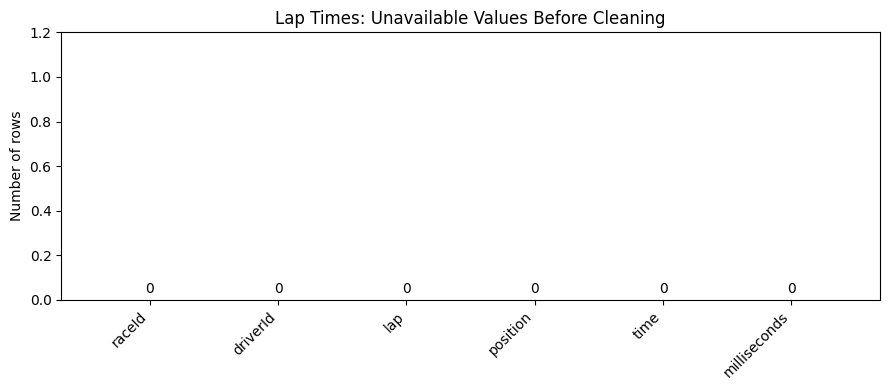

In [196]:
unavailable = missing + sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Lap Times: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Convert `time` to numeric seconds

The CSV already supplies `milliseconds`. After checking its availability, divide by 1,000 and replace `time` in `lap_times_clean`. Original text stays in `lap_times`. An independent text conversion below verifies agreement; no columns are added.


In [197]:
lap_times_clean = lap_times.copy(deep=True)
lap_times_clean = lap_times_clean.replace(r"\N", np.nan)


In [198]:
# Verify milliseconds are available wherever the original time is present.
lap_times_clean["milliseconds"] = pd.to_numeric(lap_times_clean["milliseconds"], errors="raise")
assert not (lap_times_clean["time"].notna() & lap_times_clean["milliseconds"].isna()).any(), "A recorded time has no milliseconds."

# 1,000 milliseconds = 1 second. Replace time in the cleaned copy only.
lap_times_clean["time"] = lap_times_clean["milliseconds"] / 1000


In [199]:
# Independently compare original text with the converted time.
lap_text = lap_times["time"].replace(r"\N", np.nan).astype("string")
lap_text = lap_text.where(lap_text.str.count(":").ne(1), "0:" + lap_text)
lap_text_seconds = pd.to_timedelta(lap_text, errors="raise").dt.total_seconds()
lap_matches = np.isclose(lap_text_seconds, lap_times_clean["time"], atol=0.001, rtol=0, equal_nan=True)
print("Original time values agreeing with converted seconds:", lap_matches.sum())
assert lap_matches.all(), "Original time and milliseconds disagree."


Original time values agreeing with converted seconds: 589081


### Before/after values and types

Compare the same `time` column in the original and cleaned tables. Hour-based examples demonstrate parsing support, not that unusually long records have been verified.


In [200]:
display(pd.DataFrame({
    "time BEFORE (text)": lap_times["time"].head(10),
    "time AFTER (seconds)": lap_times_clean["time"].head(10)
}))
print("time BEFORE type:", lap_times["time"].dtype)
print("time AFTER type:", lap_times_clean["time"].dtype)
hour_examples = lap_times["time"].astype("string").str.count(":").eq(2).fillna(False)
display(pd.DataFrame({
    "time BEFORE (text)": lap_times.loc[hour_examples, "time"],
    "time AFTER (seconds)": lap_times_clean.loc[hour_examples, "time"],
    "milliseconds": lap_times_clean.loc[hour_examples, "milliseconds"]
}).head(5))


,time BEFORE (text),time AFTER (seconds)
0,1:38.109,98.109
1,1:33.006,93.006
2,1:32.713,92.713
3,1:32.803,92.803
4,1:32.342,92.342
5,1:32.605,92.605
6,1:32.502,92.502
7,1:32.537,92.537
8,1:33.240,93.240
9,1:32.572,92.572


time BEFORE type: object
time AFTER type: float64


,time BEFORE (text),time AFTER (seconds),milliseconds
7916,2:05:05.152,7505.152,7505152
7985,2:05:04.226,7504.226,7504226
8020,2:05:06.656,7506.656,7506656
8089,2:05:05.034,7505.034,7505034
8165,2:05:01.488,7501.488,7501488


The cleaned `time` column contains seconds calculated from `milliseconds / 1000`. We independently converted original text to seconds and checked agreement. This verifies conversion consistency, not underlying record accuracy. Original rows and columns are preserved; no missing values are filled.


### Key and reference checks


In [201]:
key_columns = ["raceId", "driverId", "lap"]

print("Missing key values:")
display(lap_times_clean[key_columns].isna().sum())

print(
    "Duplicate race–driver–lap records:",
    lap_times_clean.duplicated(key_columns).sum()
)

# Display problem records, if any.
duplicates = lap_times_clean.duplicated(key_columns, keep=False)

if duplicates.any():
    display(
        lap_times_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert lap_times_clean[key_columns].notna().all().all(), \
    "Missing raceId, driverId, or lap found"

assert not duplicates.any(), \
    "Repeated race–driver–lap records found"

print("Passed: race–driver–lap combinations are unique and non-null.")

Missing key values:


raceId      0
driverId    0
lap         0
dtype: int64

Duplicate race–driver–lap records: 0
Passed: race–driver–lap combinations are unique and non-null.


In [202]:
unknown_races = ~lap_times_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~lap_times_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(lap_times_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(lap_times_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), \
    "Some race IDs do not exist in races"

assert not unknown_drivers.any(), \
    "Some driver IDs do not exist in drivers"

print("Passed: all race and driver IDs exist in their reference tables.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: all race and driver IDs exist in their reference tables.


In [203]:
# Deduplicate only the lookup pairs, not the lap records.
result_pairs = results[["raceId", "driverId"]].drop_duplicates()

lap_pairs = (
    lap_times_clean[["raceId", "driverId"]]
    .drop_duplicates()
)

pair_check = lap_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs.head(20))

assert unmatched_pairs.empty, \
    "Some lap records belong to driver–race pairs absent from results"

print("Passed: all lap driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all lap driver–race pairs exist in results.


The combination of raceId, driverId, and lap is unique and non-null.
All race and driver references exist, and every recorded driver–race pair
has a corresponding result record. Repeated driver–race pairs across
different laps are expected and were preserved.

### Unusual-value investigation

Long recorded durations are inspected, not automatically removed. Their cause is not established by their size alone.


In [204]:
display(
    lap_times_clean[
        ["lap", "position", "time"]
    ].describe().T
)

print("Rows with lap <= 0:",
      lap_times_clean["lap"].le(0).sum())

print("Rows with position <= 0:",
      lap_times_clean["position"].le(0).sum())

print("Rows with time <= 0:",
      lap_times_clean["time"].le(0).sum())

,count,mean,std,min,25%,50%,75%,max
lap,589081.0,30.018104,18.407126,1.000,14.000,29.000,44.00,87.000
position,589081.0,9.661951,5.528553,1.000,5.000,9.000,14.00,24.000
time,589081.0,95.799445,76.399730,55.404,82.041,90.608,101.93,7507.547


Rows with lap <= 0: 0
Rows with position <= 0: 0
Rows with time <= 0: 0


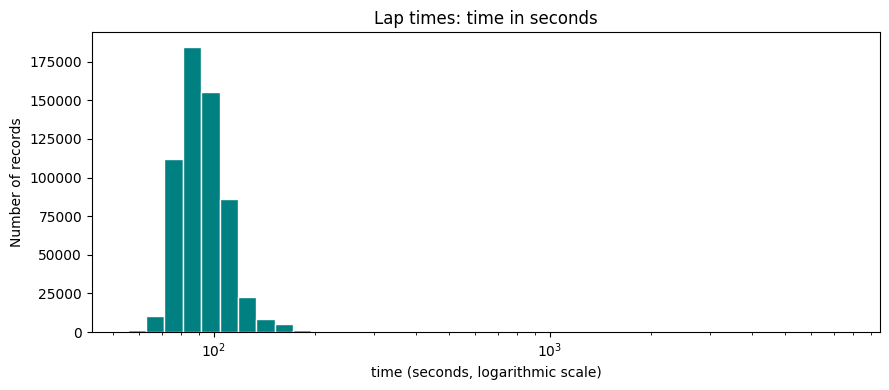

In [205]:
# Logarithmic bins show typical and unusually long durations together.
values = lap_times_clean.loc[lap_times_clean["time"] > 0, "time"].dropna()
if not values.empty:
    bins = np.geomspace(values.min(), values.max(), 40) if values.min() < values.max() else 10
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(values, bins=bins, color="teal", edgecolor="white")
    ax.set_xscale("log")
    ax.set_title("Lap times: time in seconds")
    ax.set_xlabel("time (seconds, logarithmic scale)")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()


In [206]:
print("Largest time values — flagged for investigation, not removed:")
display(
    lap_times_clean.nlargest(10, "time")[
        ["raceId", "driverId", "lap", "position",
         "time", "milliseconds"]
    ]
)

Largest time values — flagged for investigation, not removed:


,raceId,driverId,lap,position,time,milliseconds
8372,847,2,25,4,7507.547,7507547
8020,847,13,25,3,7506.656,7506656
8426,847,808,25,5,7506.243,7506243
8621,847,155,25,2,7506.095,7506095
7916,847,20,25,1,7505.152,7505152
8089,847,17,25,7,7505.034,7505034
7985,847,4,25,8,7504.226,7504226
8495,847,814,25,6,7503.980,7503980
8876,847,37,25,9,7503.795,7503795
8234,847,18,25,11,7503.775,7503775


### Final verification


In [207]:
final_checks = pd.Series({
    "Row count unchanged":
        len(lap_times_clean) == len(lap_times),

    "No remaining placeholders":
        not lap_times_clean.eq(r"\N").any().any(),

    "Key columns non-null":
        lap_times_clean[["raceId", "driverId", "lap"]]
        .notna().all().all(),

    "Race–driver–lap key unique":
        not lap_times_clean.duplicated(
            ["raceId", "driverId", "lap"]
        ).any(),

    "time is numeric seconds":
        pd.api.types.is_numeric_dtype(
            lap_times_clean["time"]
        )
})

display(final_checks.to_frame("Passed"))

assert final_checks.all(), "Investigate failed checks."

,Passed
Row count unchanged,True
No remaining placeholders,True
Key columns non-null,True
Race–driver–lap key unique,True
time is numeric seconds,True


### Lap times: cleaning and audit

- Preserved the original table and cleaned a copy.
- Inspected missing values and placeholder values before cleaning.
- Converted recorded lap durations into numeric seconds.
- Verified conversion against the milliseconds column.
- Checked uniqueness and non-nullness of the race–driver–lap key.
- Verified race, driver, and driver–race references.
- Examined duration distributions and the longest records.
- Preserved unusually long durations pending investigation.
- Did not fill missing values or remove lap records.
- Current-race lap information will not be used as pre-race prediction inputs.

In [208]:
lap_times_clean.info()
assert lap_times_clean.columns.equals(lap_times.columns), "Unexpected added or removed lap columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 589081 entries, 0 to 589080
Data columns (total 6 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   raceId        589081 non-null  int64  
 1   driverId      589081 non-null  int64  
 2   lap           589081 non-null  int64  
 3   position      589081 non-null  int64  
 4   time          589081 non-null  float64
 5   milliseconds  589081 non-null  int64  
dtypes: float64(1), int64(5)
memory usage: 27.0 MB


# 3. pit_stops.csv

### Before-cleaning inspection

Each row represents one recorded pit stop. The key is `(raceId, driverId, stop)`. `time` is a clock time; `duration` is elapsed time.


In [209]:
print("Rows:", pit_stops.shape[0])
print("Columns:", pit_stops.shape[1])

display(pit_stops.head(10))
pit_stops.info()

Rows: 11371
Columns: 7


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426
3,841,4,1,12,17:22:34,23.251,23251
4,841,13,1,13,17:24:10,23.842,23842
5,841,22,1,13,17:24:29,23.643,23643
6,841,20,1,14,17:25:17,22.603,22603
7,841,814,1,14,17:26:03,24.863,24863
8,841,816,1,14,17:26:50,25.259,25259
9,841,67,1,15,17:27:34,25.342,25342


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   raceId        11371 non-null  int64 
 1   driverId      11371 non-null  int64 
 2   stop          11371 non-null  int64 
 3   lap           11371 non-null  int64 
 4   time          11371 non-null  object
 5   duration      11371 non-null  object
 6   milliseconds  11371 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 622.0+ KB


In [210]:
pit_missing = pit_stops.isna().sum()
pit_sentinels = pit_stops.eq(r"\N").sum()

pit_inspection = pd.DataFrame({
    "Data type": pit_stops.dtypes.astype(str),
    "Recognized missing": pit_missing,
    r"\N placeholders": pit_sentinels,
    "Total unavailable": pit_missing + pit_sentinels,
    "Unavailable %": (
        (pit_missing + pit_sentinels) / len(pit_stops) * 100
    ).round(2)
})

display(pit_inspection)

,Data type,Recognized missing,\N placeholders,Total unavailable,Unavailable %
raceId,int64,0,0,0,0.0
driverId,int64,0,0,0,0.0
stop,int64,0,0,0,0.0
lap,int64,0,0,0,0.0
time,object,0,0,0,0.0
duration,object,0,0,0,0.0
milliseconds,int64,0,0,0,0.0


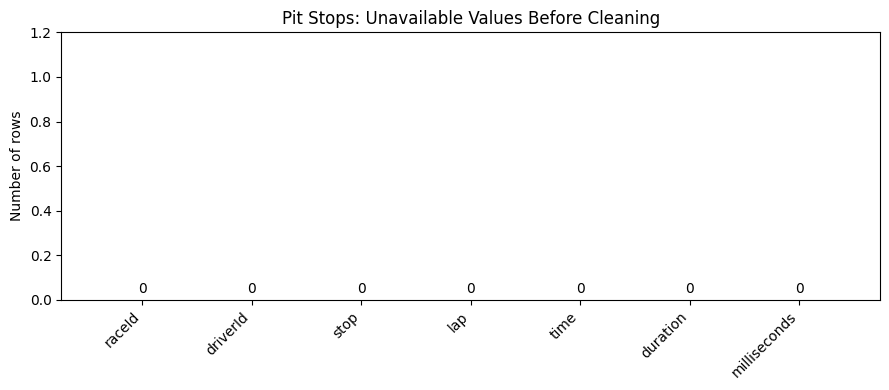

In [211]:
unavailable = pit_missing + pit_sentinels

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    unavailable.index,
    unavailable.values,
    color="steelblue"
)

ax.bar_label(bars, padding=3)
ax.set_title("Pit Stops: Unavailable Values Before Cleaning")
ax.set_ylabel("Number of rows")
ax.set_ylim(0, max(1, unavailable.max()) * 1.2)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [212]:
display(
    pit_stops.select_dtypes(include="number").describe().T
)

# Show examples of durations written with minutes.
minute_format = (
    pit_stops["duration"]
    .astype("string")
    .str.contains(":", na=False)
)

print("Durations containing a colon:", minute_format.sum())

display(
    pit_stops.loc[
        minute_format,
        ["raceId", "driverId", "stop", "lap",
         "duration", "milliseconds"]
    ].head(10)
)

,count,mean,std,min,25%,50%,75%,max
raceId,11371.0,981.194882,92.326831,841.0,895.0,971.0,1065.0,1144.0
driverId,11371.0,549.734500,383.734981,1.0,20.0,817.0,835.0,862.0
stop,11371.0,1.787969,1.521462,1.0,1.0,2.0,2.0,70.0
lap,11371.0,25.387389,14.831497,1.0,13.0,25.0,36.0,78.0
milliseconds,11371.0,85230.495559,310427.261089,12897.0,21937.5,23606.0,26544.0,3069017.0


Durations containing a colon: 517


,raceId,driverId,stop,lap,duration,milliseconds
751,853,817,1,1,16:44.718,1004718
2419,881,814,2,20,2:03.124,123124
2420,881,16,2,22,1:29.401,89401
2421,881,18,3,35,1:44.833,104833
2422,884,16,1,8,1:14.026,74026
2533,888,17,1,8,2:42.042,162042
2713,893,154,3,33,1:13.009,73009
2802,894,16,3,38,1:11.445,71445
3089,901,817,3,40,1:49.329,109329
3159,903,13,1,10,1:18.277,78277


### Placeholder handling and semantic typing


In [213]:
pit_stops_clean = pit_stops.copy(deep=True)

pit_stops_clean = pit_stops_clean.replace(r"\N", np.nan)

In [214]:
# Verify milliseconds are available wherever the original duration is present.
pit_stops_clean["milliseconds"] = pd.to_numeric(pit_stops_clean["milliseconds"], errors="raise")
assert not (pit_stops_clean["duration"].notna() & pit_stops_clean["milliseconds"].isna()).any(), "A recorded duration has no milliseconds."

pit_stops_clean["duration"] = pit_stops_clean["milliseconds"] / 1000


In [215]:
# time is a clock reading, not an elapsed duration. Keep its text format.
# Validate the format without changing the column or inventing a date.
clock_check = pd.to_datetime(pit_stops_clean["time"], format="%H:%M:%S", errors="coerce")
invalid_clock = pit_stops_clean["time"].notna() & clock_check.isna()
print("Invalid non-missing time values:", invalid_clock.sum())
assert not invalid_clock.any(), "Investigate invalid clock readings."


Invalid non-missing time values: 0


In [216]:
# Independently check both original duration formats against milliseconds.
pit_text = pit_stops["duration"].replace(r"\N", np.nan).astype("string")
pit_text = pit_text.where(pit_text.str.count(":").ne(1), "0:" + pit_text)
pit_text = pit_text.where(pit_text.str.contains(":", na=True), pit_text + "s")
pit_text_seconds = pd.to_timedelta(pit_text, errors="raise").dt.total_seconds()
pit_matches = np.isclose(pit_text_seconds, pit_stops_clean["duration"], atol=0.001, rtol=0, equal_nan=True)
print("Original duration values agreeing with converted seconds:", pit_matches.sum())
assert pit_matches.all(), "Original duration and milliseconds disagree."


Original duration values agreeing with converted seconds: 11371


### Before/after evidence


In [217]:
display(pd.DataFrame({
    "duration BEFORE (text)": pit_stops["duration"].head(10),
    "duration AFTER (seconds)": pit_stops_clean["duration"].head(10),
    "time BEFORE (text)": pit_stops["time"].head(10),
    "time AFTER (clock text unchanged)": pit_stops_clean["time"].head(10)
}))
print("duration BEFORE type:", pit_stops["duration"].dtype)
print("duration AFTER type:", pit_stops_clean["duration"].dtype)
print("time BEFORE type:", pit_stops["time"].dtype)
print("time AFTER type:", pit_stops_clean["time"].dtype)
print("Rows BEFORE:", len(pit_stops))
print("Rows AFTER:", len(pit_stops_clean))
print("Missing duration AFTER:", pit_stops_clean["duration"].isna().sum())
print("Missing time AFTER:", pit_stops_clean["time"].isna().sum())


,duration BEFORE (text),duration AFTER (seconds),time BEFORE (text),time AFTER (clock text unchanged)
0,26.898,26.898,17:05:23,17:05:23
1,25.021,25.021,17:05:52,17:05:52
2,23.426,23.426,17:20:48,17:20:48
3,23.251,23.251,17:22:34,17:22:34
4,23.842,23.842,17:24:10,17:24:10
5,23.643,23.643,17:24:29,17:24:29
6,22.603,22.603,17:25:17,17:25:17
7,24.863,24.863,17:26:03,17:26:03
8,25.259,25.259,17:26:50,17:26:50
9,25.342,25.342,17:27:34,17:27:34


duration BEFORE type: object
duration AFTER type: float64
time BEFORE type: object
time AFTER type: object
Rows BEFORE: 11371
Rows AFTER: 11371
Missing duration AFTER: 0
Missing time AFTER: 0


The cleaned `duration` contains numeric seconds from `milliseconds / 1000`, checked independently against the original text. `time` is a clock reading, not a duration: its text is preserved and its format validated. No date or timezone is inferred. Original tables remain unchanged; no columns are added and missing values are not filled.


### Pit-stop source verification — records preserved

Large durations are preserved. The [official British 2022 timing](https://www.formula1.com/en/results/2022/races/1114/great-britain/pit-stop-summary) matches Stroll's 51:09.017. The [Dutch 2023 timing](https://www.formula1.com/en/results/2023/races/1217/netherlands/pit-stop-summary) matches Verstappen's 41:23.382. The [Japanese 2023 FIA timing](https://www.fia.com/sites/default/files/2023_17_jpn_f1_r0_timing_racepitstopsummary_v01.pdf) matches Perez's 41:25.913. Recorded durations can include race interruptions or garage time; they are not simply stationary tyre-change times.

The [Monaco 2024 FIA sheet](https://www.fia.com/sites/default/files/2024_08_mon_f1_r0_timing_racepitstopsummary_v01.pdf) indicates seven swapped stop/lap pairs in race 1128. These are documented only; their recorded values are preserved and no swap correction is applied.

[British 2014 timing](https://www.formula1.com/en/results/2014/races/906/great-britain/pit-stop-summary) records Chilton's first stop, absent from this CSV. [Singapore 2019 FIA timing](https://www.fia.com/sites/default/files/2019_15_sgp_f1_r0_timing_racepitstopsummary_v01.pdf) records Sainz's first stop, also absent. Remaining stop numbers are preserved. No missing rows are reconstructed.


### Key and reference checks


In [218]:
key_columns = ["raceId", "driverId", "stop"]

display(
    pit_stops_clean[key_columns]
    .isna()
    .sum()
    .to_frame("Missing key values")
)

duplicates = pit_stops_clean.duplicated(
    key_columns, keep=False
)

print("Extra duplicate key rows:",
      pit_stops_clean.duplicated(key_columns).sum())

if duplicates.any():
    display(
        pit_stops_clean.loc[duplicates]
        .sort_values(key_columns)
        .head(20)
    )

assert pit_stops_clean[key_columns].notna().all().all(), \
    "Missing key values found"

assert not duplicates.any(), \
    "Repeated race–driver–stop combinations found"

print("Passed: the key is unique and non-null.")

,Missing key values
raceId,0
driverId,0
stop,0


Extra duplicate key rows: 0
Passed: the key is unique and non-null.


In [219]:
unknown_races = ~pit_stops_clean["raceId"].isin(races["raceId"])
unknown_drivers = ~pit_stops_clean["driverId"].isin(drivers["driverId"])

print("Rows with unknown race IDs:", unknown_races.sum())
print("Rows with unknown driver IDs:", unknown_drivers.sum())

if unknown_races.any():
    display(pit_stops_clean.loc[unknown_races].head(20))

if unknown_drivers.any():
    display(pit_stops_clean.loc[unknown_drivers].head(20))

assert not unknown_races.any(), "Unknown race IDs found"
assert not unknown_drivers.any(), "Unknown driver IDs found"

print("Passed: race and driver references exist.")

Rows with unknown race IDs: 0
Rows with unknown driver IDs: 0
Passed: race and driver references exist.


In [220]:
pit_pairs = pit_stops_clean[
    ["raceId", "driverId"]
].drop_duplicates()

result_pairs = results[
    ["raceId", "driverId"]
].drop_duplicates()

pair_check = pit_pairs.merge(
    result_pairs,
    on=["raceId", "driverId"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

unmatched_pairs = pair_check.loc[
    pair_check["_merge"].eq("left_only"),
    ["raceId", "driverId"]
]

print("Driver–race pairs absent from results:", len(unmatched_pairs))

if not unmatched_pairs.empty:
    display(unmatched_pairs)

assert unmatched_pairs.empty, \
    "Some pit-stop driver–race pairs are absent from results"

print("Passed: all driver–race pairs exist in results.")

Driver–race pairs absent from results: 0
Passed: all driver–race pairs exist in results.


### Unusual stop-number investigation

The sequence check flags groups for review; it does not establish that a record is wrong or authorize renumbering.


In [221]:
stop_summary = (
    pit_stops_clean.groupby(["raceId", "driverId"])
    .agg(
        recorded_stops=("stop", "size"),
        first_stop_number=("stop", "min"),
        last_stop_number=("stop", "max")
    )
    .reset_index()
)

# With unique positive integer stop numbers, these checks identify
# sequences that do not run continuously from 1 to the record count.
unusual_sequences = stop_summary[
    stop_summary["first_stop_number"].ne(1)
    | stop_summary["last_stop_number"].ne(
        stop_summary["recorded_stops"]
    )
]

print("Driver–race groups with unusual stop numbering:",
      len(unusual_sequences))

display(unusual_sequences.head(20))

print("Largest recorded stop numbers:")
display(
    pit_stops_clean.nlargest(10, "stop")[
        ["raceId", "driverId", "stop", "lap", "duration"]
    ]
)

Driver–race groups with unusual stop numbering: 8


,raceId,driverId,recorded_stops,first_stop_number,last_stop_number
1451,908,820,2,2,3
3458,1024,832,1,2,2
5252,1128,1,2,1,51
5255,1128,822,2,1,15
5256,1128,830,2,1,52
5258,1128,840,3,1,48
5265,1128,855,2,1,70
5267,1128,858,2,1,57


Largest recorded stop numbers:


,raceId,driverId,stop,lap,duration
10857,1128,855,70,2,24.367
10856,1128,858,57,2,24.384
10855,1128,830,52,2,23.813
10854,1128,1,51,2,24.232
10853,1128,840,48,3,28.211
10852,1128,840,42,2,24.132
10851,1128,822,15,2,24.239
10184,1111,840,7,64,33.553
10187,1111,859,7,64,31.306
10189,1111,847,7,67,22.379


In [222]:
# Show all records in the flagged driver–race groups.
flagged_stops = pit_stops_clean.merge(
    unusual_sequences[["raceId", "driverId"]],
    on=["raceId", "driverId"],
    how="inner",
    validate="many_to_one"
)

display(
    flagged_stops[[
        "raceId", "driverId", "stop", "lap",
        "time", "duration"
    ]].sort_values(["raceId", "driverId", "time"])
)

,raceId,driverId,stop,lap,time,duration
0,908,820,2,2,14:09:26,23.154
1,908,820,3,29,14:56:02,29.737
2,1024,832,2,35,21:20:33,30.623
4,1128,1,1,1,15:05:00,2375.369
12,1128,1,51,2,16:52:10,24.232
7,1128,822,1,1,15:05:19,2394.053
9,1128,822,15,2,16:04:57,24.239
3,1128,830,1,1,15:04:57,2372.670
13,1128,830,52,2,16:53:26,23.813
5,1128,840,1,1,15:05:10,2383.588


### Duration investigation

A long recorded duration may reflect unusual race circumstances. Keep it pending verification.


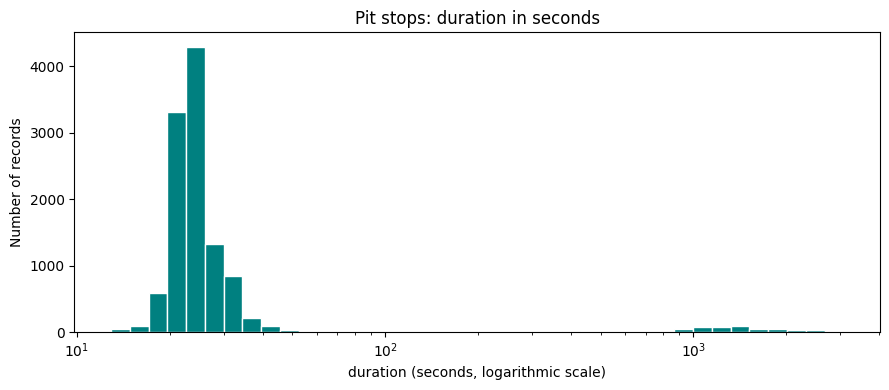

Rows with duration <= 0: 0


,raceId,driverId,stop,lap,duration
9156,1083,840,1,1,3069.017
9155,1083,20,1,1,3067.301
9157,1083,854,1,1,3065.174
9154,1083,825,1,1,3063.613
9152,1083,817,1,1,3063.314
9151,1083,822,1,1,3055.732
9147,1083,4,1,1,3055.700
9150,1083,849,1,1,3051.904
9153,1083,842,1,1,3048.950
9145,1083,1,1,1,3046.888


In [223]:
# Logarithmic bins show typical and unusually long durations together.
values = pit_stops_clean.loc[pit_stops_clean["duration"] > 0, "duration"].dropna()
if not values.empty:
    bins = np.geomspace(values.min(), values.max(), 40) if values.min() < values.max() else 10
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(values, bins=bins, color="teal", edgecolor="white")
    ax.set_xscale("log")
    ax.set_title("Pit stops: duration in seconds")
    ax.set_xlabel("duration (seconds, logarithmic scale)")
    ax.set_ylabel("Number of records")
    plt.tight_layout()
    plt.show()

print("Rows with duration <= 0:", pit_stops_clean["duration"].le(0).sum())
display(pit_stops_clean.nlargest(10, "duration")[["raceId", "driverId", "stop", "lap", "duration"]])


### Pit-stop audit findings and deferred work

Duration conversion, milliseconds consistency, key uniqueness and reference checks are implemented above. Eight driver–race groups have unusual stop numbering. Source comparisons document seven swapped stop/lap pairs in Monaco 2024 and missing first-stop records for Chilton (Britain 2014) and Sainz (Singapore 2019). These findings are documented without changing stop or lap values, renumbering remaining stops, adding rows or deleting records. Large durations remain preserved. Missing-value filling is deferred. Current-race pit-stop information is excluded from pre-race model inputs. Raw CSVs remain unchanged.


In [224]:
pit_final_checks = pd.Series({
    "Row count unchanged": len(pit_stops_clean) == len(pit_stops),
    "No remaining placeholders": not pit_stops_clean.eq(r"\N").any().any(),
    "Key non-null": pit_stops_clean[["raceId", "driverId", "stop"]].notna().all().all(),
    "Key unique": not pit_stops_clean.duplicated(["raceId", "driverId", "stop"]).any(),
    "Clock text unchanged": pit_stops_clean["time"].equals(pit_stops["time"].replace(r"\N", np.nan)),
    "duration is numeric seconds": pd.api.types.is_numeric_dtype(pit_stops_clean["duration"]),
    "Duration missingness preserved": pit_stops_clean["duration"].isna().sum() == pit_stops["duration"].replace(r"\N", np.nan).isna().sum(),
    "Clock missingness preserved": pit_stops_clean["time"].isna().sum() == pit_stops["time"].replace(r"\N", np.nan).isna().sum()
})
display(pit_final_checks.to_frame("Passed"))
assert pit_final_checks.all(), "Investigate failed pit-stop checks."


,Passed
Row count unchanged,True
No remaining placeholders,True
Key non-null,True
Key unique,True
Clock text unchanged,True
duration is numeric seconds,True
Duration missingness preserved,True
Clock missingness preserved,True


In [225]:
pit_stops_clean.info()
assert pit_stops_clean.columns.equals(pit_stops.columns), "Unexpected added or removed pit columns"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11371 entries, 0 to 11370
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   raceId        11371 non-null  int64  
 1   driverId      11371 non-null  int64  
 2   stop          11371 non-null  int64  
 3   lap           11371 non-null  int64  
 4   time          11371 non-null  object 
 5   duration      11371 non-null  float64
 6   milliseconds  11371 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 622.0+ KB


# Mohamed — constructor standings, constructors, driver standings


## Constructor standings


In [216]:
constructor_standings.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [217]:
constructor_standings_clean  =  pd.read_csv(DATA_DIR / "constructor_standings.csv",na_values=[r"\N"]) 
constructor_standings_clean.head()

,constructorStandingsId,raceId,constructorId,points,position,positionText,wins
0,1,18,1,14.0,1,1,1
1,2,18,2,8.0,3,3,0
2,3,18,3,9.0,2,2,0
3,4,18,4,5.0,4,4,0
4,5,18,5,2.0,5,5,0


In [218]:
constructor_standings_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13391 entries, 0 to 13390
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   constructorStandingsId  13391 non-null  int64  
 1   raceId                  13391 non-null  int64  
 2   constructorId           13391 non-null  int64  
 3   points                  13391 non-null  float64
 4   position                13391 non-null  int64  
 5   positionText            13391 non-null  object 
 6   wins                    13391 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 732.4+ KB


In [219]:
# Check the record ID.
record_id = "constructorStandingsId"

print("Missing constructorStandingsId:",
      constructor_standings_clean[record_id].isna().sum())

print("Duplicate constructorStandingsId:",
      constructor_standings_clean[record_id].duplicated().sum())

assert constructor_standings_clean[record_id].notna().all(), \
    "Missing constructorStandingsId found"

assert constructor_standings_clean[record_id].is_unique, \
    "Duplicate constructorStandingsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "constructorId"]

print("\nMissing race and constructor IDs:")
display(constructor_standings_clean[pair_columns].isna().sum())

print("Duplicate race–constructor pairs:",
      constructor_standings_clean.duplicated(pair_columns).sum())

assert constructor_standings_clean[pair_columns].notna().all().all(), \
    "Missing raceId or constructorId found"

assert not constructor_standings_clean.duplicated(pair_columns).any(), \
    "Duplicate race–constructor pairs found"

print("\nPassed: record IDs and race–constructor pairs are unique and non-null.")

Missing constructorStandingsId: 0
Duplicate constructorStandingsId: 0

Missing race and constructor IDs:


raceId           0
constructorId    0
dtype: int64

Duplicate race–constructor pairs: 0

Passed: record IDs and race–constructor pairs are unique and non-null.


In [220]:
# Find rows with missing or unknown race IDs.
invalid_races = constructor_standings_clean[
    constructor_standings_clean["raceId"].isna()
    | ~constructor_standings_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_constructors = constructor_standings_clean[
    constructor_standings_clean["constructorId"].isna()
    | ~constructor_standings_clean["constructorId"].isin(
        constructors["constructorId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown constructor IDs:", len(invalid_constructors))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_constructors.empty:
    display(invalid_constructors)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_constructors.empty, \
    "Some constructor IDs are missing or absent from constructors"

print("Passed: all race and constructor IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown constructor IDs: 0
Passed: all race and constructor IDs exist in their reference tables.


## Constructors


In [221]:
constructors.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [222]:
constructors_clean  =  pd.read_csv(DATA_DIR / "constructors.csv",na_values=[r"\N"]) 
constructors_clean.head()

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso


In [223]:
constructors_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   constructorId   212 non-null    int64 
 1   constructorRef  212 non-null    object
 2   name            212 non-null    object
 3   nationality     212 non-null    object
 4   url             212 non-null    object
dtypes: int64(1), object(4)
memory usage: 8.4+ KB


In [224]:
# Check the record ID.
record_id = "constructorId"

print("Missing constructorId:",
      constructors_clean[record_id].isna().sum())

print("Duplicate constructorId:",
      constructors_clean[record_id].duplicated().sum())

assert constructors_clean[record_id].notna().all(), \
    "Missing constructorId found"

assert constructors_clean[record_id].is_unique, \
    "Duplicate constructorId found"


Missing constructorId: 0
Duplicate constructorId: 0


## Driver standings


In [225]:
driver_standings.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [226]:
driver_standings_clean  =  pd.read_csv(DATA_DIR / "driver_standings.csv",na_values=[r"\N"]) 
driver_standings_clean.head()

,driverStandingsId,raceId,driverId,points,position,positionText,wins
0,1,18,1,10.0,1,1,1
1,2,18,2,8.0,2,2,0
2,3,18,3,6.0,3,3,0
3,4,18,4,5.0,4,4,0
4,5,18,5,4.0,5,5,0


In [227]:
driver_standings_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34863 entries, 0 to 34862
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   driverStandingsId  34863 non-null  int64  
 1   raceId             34863 non-null  int64  
 2   driverId           34863 non-null  int64  
 3   points             34863 non-null  float64
 4   position           34863 non-null  int64  
 5   positionText       34863 non-null  object 
 6   wins               34863 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.9+ MB


In [228]:
# Check the record ID.
record_id = "driverStandingsId"

print("Missing driverStandingsId:",
      driver_standings_clean[record_id].isna().sum())

print("Duplicate driverStandingsId:",
      driver_standings_clean[record_id].duplicated().sum())

assert driver_standings_clean[record_id].notna().all(), \
    "Missing driverStandingsId found"

assert driver_standings_clean[record_id].is_unique, \
    "Duplicate driverStandingsId found"


# Check the race–constructor combination.
pair_columns = ["raceId", "driverId"]

print("\nMissing race and driver IDs:")
display(driver_standings_clean[pair_columns].isna().sum())

print("Duplicate race–driver pairs:",
      driver_standings_clean.duplicated(pair_columns).sum())

assert driver_standings_clean[pair_columns].notna().all().all(), \
    "Missing raceId or driverID found"

assert not driver_standings_clean.duplicated(pair_columns).any(), \
    "Duplicate race–driver pairs found"

print("\nPassed: record IDs and race–drivers pairs are unique and non-null.")

Missing driverStandingsId: 0
Duplicate driverStandingsId: 0

Missing race and driver IDs:


raceId      0
driverId    0
dtype: int64

Duplicate race–driver pairs: 0

Passed: record IDs and race–drivers pairs are unique and non-null.


In [229]:
# Find rows with missing or unknown race IDs.
invalid_races = driver_standings_clean[
    driver_standings_clean["raceId"].isna()
    | ~driver_standings_clean["raceId"].isin(races["raceId"])
]

# Find rows with missing or unknown constructor IDs.
invalid_drivers = driver_standings_clean[
    driver_standings_clean["driverId"].isna()
    | ~driver_standings_clean["driverId"].isin(
        drivers["driverId"]
    )
]

print("Rows with missing or unknown race IDs:", len(invalid_races))
print("Rows with missing or unknown drivers IDs:", len(invalid_drivers))

if not invalid_races.empty:
    display(invalid_races)

if not invalid_drivers.empty:
    display(invalid_drivers)

assert invalid_races.empty, \
    "Some race IDs are missing or absent from races"

assert invalid_drivers.empty, \
    "Some drivers IDs are missing or absent from drivers"

print("Passed: all race and drivers IDs exist in their reference tables.")

Rows with missing or unknown race IDs: 0
Rows with missing or unknown drivers IDs: 0
Passed: all race and drivers IDs exist in their reference tables.


# Kareem — qualifying, races, results


### **qualifying table**

In [230]:
print("shape:", qualifying.shape)
print("columns:", list(qualifying.columns))
qualifying.head()

shape: (10494, 9)
columns: ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position', 'q1', 'q2', 'q3']


,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [231]:
before = pd.DataFrame({
    "sentinel (\\N)": (qualifying == r"\N").sum(),
    "blank ('')":     (qualifying == "").sum(),
})
before["total missing"] = before.sum(axis=1)
before["% missing"] = (100 * before["total missing"] / len(qualifying)).round(2)
before

,sentinel (\N),blank (''),total missing,% missing
qualifyId,0,0,0,0.00
raceId,0,0,0,0.00
driverId,0,0,0,0.00
constructorId,0,0,0,0.00
number,0,0,0,0.00
position,0,0,0,0.00
q1,156,0,156,1.49
q2,4625,0,4625,44.07
q3,6819,0,6819,64.98


In [232]:
##removed placeholders to null values

qualifying_clean =  pd.read_csv(DATA_DIR / "qualifying.csv", na_values=[r"\N"]) 
qualifying_clean.head()

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236


In [233]:
qualifying_clean.isnull().sum()

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4647
q3               6865
dtype: int64

In [234]:
check = pd.DataFrame({
    "missing_before": before["total missing"],
    "NaN_after": qualifying_clean.isnull().sum(),
})
check["match"] = check["missing_before"] == check["NaN_after"]
check

,missing_before,NaN_after,match
qualifyId,0,0,True
raceId,0,0,True
driverId,0,0,True
constructorId,0,0,True
number,0,0,True
position,0,0,True
q1,156,156,True
q2,4625,4647,False
q3,6819,6865,False


In [235]:
def to_seconds(t):
    if pd.isna(t):
        return np.nan
    minutes, seconds = str(t).split(":")
    return int(minutes) * 60 + float(seconds)

for col in ["q1", "q2", "q3"]:
    qualifying_clean[col + "_sec"] = qualifying_clean[col].map(to_seconds)

qualifying_clean[["q1", "q1_sec", "q2", "q2_sec", "q3", "q3_sec"]].head()

,q1,q1_sec,q2,q2_sec,q3,q3_sec
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236


In [236]:
for col in ["q1", "q2", "q3"]:
    lost = (qualifying_clean[col].notna() & qualifying_clean[col + "_sec"].isna()).sum()
    print(col, "failed conversions:", lost)

q1 failed conversions: 0
q2 failed conversions: 0
q3 failed conversions: 0


In [237]:
n_dup = qualifying_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("duplicate (raceId, driverId) pairs:", n_dup)

duplicate (raceId, driverId) pairs: 0


In [238]:
print("qualifyId unique  :", qualifying_clean["qualifyId"].is_unique)
print("qualifyId no nulls:", qualifying_clean["qualifyId"].notna().all())

qualifyId unique  : True
qualifyId no nulls: True


In [239]:
races_ids        = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId"])["raceId"]
drivers_ids      = pd.read_csv(DATA_DIR / "drivers.csv", usecols=["driverId"])["driverId"]
constructors_ids = pd.read_csv(DATA_DIR / "constructors.csv", usecols=["constructorId"])["constructorId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids)]:
    orphans = int((~qualifying_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"qualifying.{col}", "points to": parent,
                 "null values": int(qualifying_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,qualifying.raceId,races.raceId,0,0,True
1,qualifying.driverId,drivers.driverId,0,0,True
2,qualifying.constructorId,constructors.constructorId,0,0,True


### **races table**

In [240]:
print("shape:", races.shape)
print("columns:", list(races.columns))
races.head()

shape: (1125, 18)
columns: ['raceId', 'year', 'round', 'circuitId', 'name', 'date', 'time', 'url', 'fp1_date', 'fp1_time', 'fp2_date', 'fp2_time', 'fp3_date', 'fp3_time', 'quali_date', 'quali_time', 'sprint_date', 'sprint_time']


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


In [241]:
before_r = pd.DataFrame({"sentinel (\\N)": (races == r"\N").sum()})
before_r["% missing"] = (100 * before_r["sentinel (\\N)"] / len(races)).round(2)
before_r

,sentinel (\N),% missing
raceId,0,0.00
year,0,0.00
round,0,0.00
circuitId,0,0.00
name,0,0.00
date,0,0.00
time,731,64.98
url,0,0.00
fp1_date,1035,92.00
fp1_time,1057,93.96


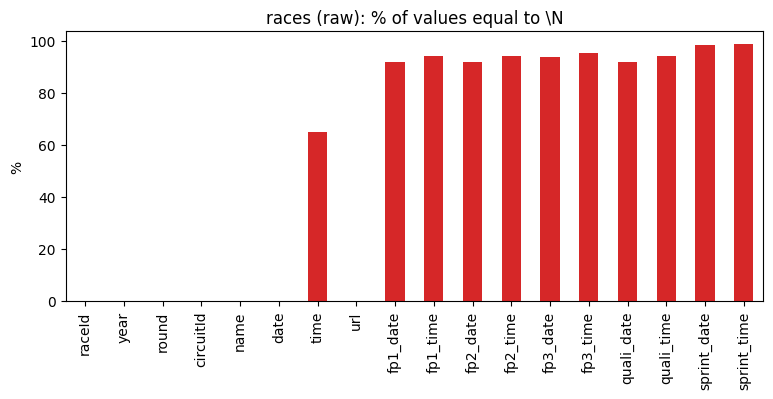

In [242]:
before_r["% missing"].plot(kind="bar", color="tab:red", figsize=(9, 3.5),
                           title="races (raw): % of values equal to \\N")
plt.ylabel("%")
plt.show()

In [243]:
races_clean = pd.read_csv(DATA_DIR / "races.csv", keep_default_na=False, na_values=[r"\N"])
races_clean.head()

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [244]:
check_r = pd.DataFrame({"sentinel_before": before_r["sentinel (\\N)"],
                        "NaN_after": races_clean.isnull().sum()})
check_r["match"] = check_r["sentinel_before"] == check_r["NaN_after"]
check_r

,sentinel_before,NaN_after,match
raceId,0,0,True
year,0,0,True
round,0,0,True
circuitId,0,0,True
name,0,0,True
date,0,0,True
time,731,731,True
url,0,0,True
fp1_date,1035,1035,True
fp1_time,1057,1057,True


In [245]:
date_cols = [c for c in ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
             if c in races_clean.columns]

for col in date_cols:
    n_before = races_clean[col].isna().sum()
    races_clean[col] = pd.to_datetime(races_clean[col], errors="coerce")
    print(col, "| new missing values created:", races_clean[col].isna().sum() - n_before)

races_clean[date_cols].dtypes

date | new missing values created: 0
fp1_date | new missing values created: 0
fp2_date | new missing values created: 0
fp3_date | new missing values created: 0
quali_date | new missing values created: 0
sprint_date | new missing values created: 0


date           datetime64[ns]
fp1_date       datetime64[ns]
fp2_date       datetime64[ns]
fp3_date       datetime64[ns]
quali_date     datetime64[ns]
sprint_date    datetime64[ns]
dtype: object

In [246]:
n_before = races_clean["time"].isna().sum()
races_clean["race_start_time"] = pd.to_timedelta(races_clean["time"])
print("new missing values created:", races_clean["race_start_time"].isna().sum() - n_before)
races_clean[["time", "race_start_time"]].dropna().head()

new missing values created: 0


,time,race_start_time
0,06:00:00,0 days 06:00:00
1,09:00:00,0 days 09:00:00
2,07:00:00,0 days 07:00:00
3,12:00:00,0 days 12:00:00
4,12:00:00,0 days 12:00:00


In [247]:
print("raceId unique  :", races_clean["raceId"].is_unique)
print("raceId no nulls:", races_clean["raceId"].notna().all())
print("(year, round) unique:", not races_clean.duplicated(["year", "round"]).any())

raceId unique  : True
raceId no nulls: True
(year, round) unique: True


In [248]:
circuits_ids = pd.read_csv(DATA_DIR / "circuits.csv", usecols=["circuitId"])["circuitId"]
seasons_ids  = pd.read_csv(DATA_DIR / "seasons.csv", usecols=["year"])["year"]

rows = []
for col, parent, ids in [("circuitId", "circuits.circuitId", circuits_ids),
                         ("year", "seasons.year", seasons_ids)]:
    orphans = int((~races_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"races.{col}", "points to": parent,
                 "null values": int(races_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,races.circuitId,circuits.circuitId,0,0,True
1,races.year,seasons.year,0,0,True


In [249]:
print("raceId order matches date order:", races_clean.sort_values("raceId")["date"].is_monotonic_increasing)

rounds = races_clean.groupby("year")["round"].agg(n_races="count", first="min", last="max")
rounds["gap"] = rounds["last"] - rounds["n_races"]
print("seasons with a gap or not starting at round 1:")
rounds[(rounds["first"] != 1) | (rounds["gap"] != 0)]

raceId order matches date order: False
seasons with a gap or not starting at round 1:


,n_races,first,last,gap
year,,,,


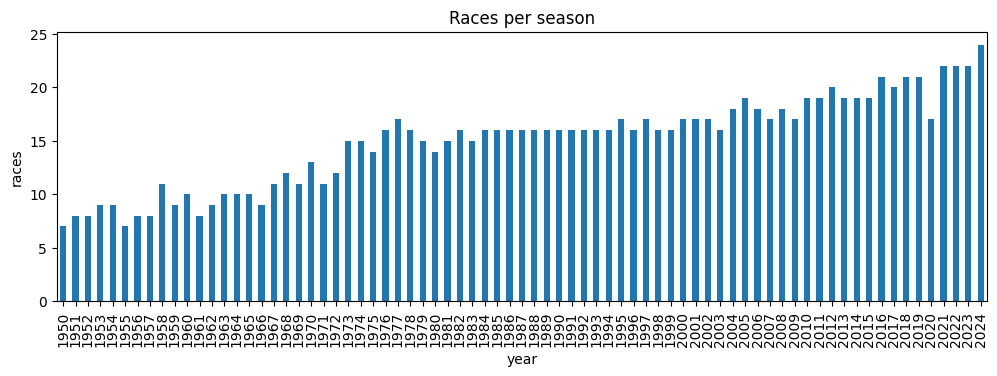

In [250]:
races_clean.groupby("year").size().plot(kind="bar", figsize=(12, 3.5), title="Races per season")
plt.ylabel("races")
plt.show()

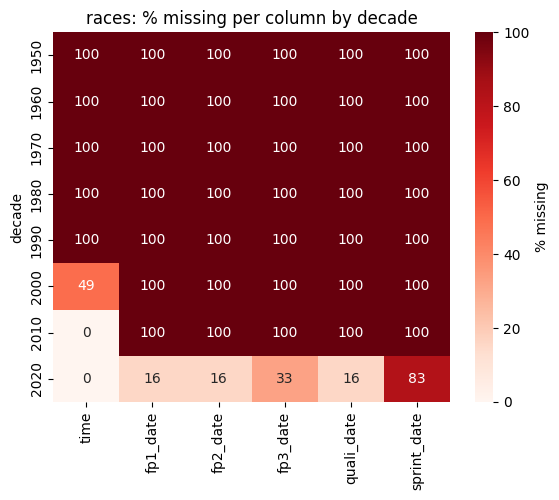

In [251]:
import seaborn as sns

sched = [c for c in ["time", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
         if c in races_clean.columns]
miss_dec = (races_clean.assign(decade=(races_clean["year"] // 10) * 10)
                       .groupby("decade")[sched]
                       .apply(lambda d: d.isna().mean() * 100))

sns.heatmap(miss_dec, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("races: % missing per column by decade")
plt.show()

In [252]:
pd.DataFrame({
    "rows": [len(races), len(races_clean)],
    "columns": [races.shape[1], races_clean.shape[1]],
    "missing values": [int(before_r["sentinel (\\N)"].sum()), int(races_clean.isnull().sum().sum())],
    "text '\\N' left": [int(before_r["sentinel (\\N)"].sum()), 0],
}, index=["before", "after"])

,rows,columns,missing values,text '\N' left
before,1125,18,11349,11349
after,1125,19,12080,0


### **Results table** 

In [253]:
print("shape:", results.shape)
print("columns:", list(results.columns))
results.head()

shape: (26759, 18)
columns: ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position', 'positionText', 'positionOrder', 'points', 'laps', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'statusId']


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [254]:
before_res = pd.DataFrame({"sentinel (\\N)": (results == r"\N").sum()})
before_res["% missing"] = (100 * before_res["sentinel (\\N)"] / len(results)).round(2)
before_res

,sentinel (\N),% missing
resultId,0,0.00
raceId,0,0.00
driverId,0,0.00
constructorId,0,0.00
number,6,0.02
grid,0,0.00
position,10953,40.93
positionText,0,0.00
positionOrder,0,0.00
points,0,0.00


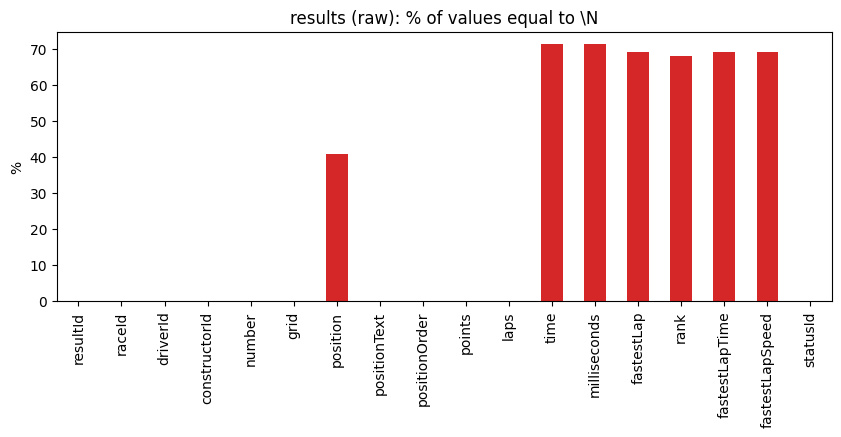

In [255]:
before_res["% missing"].plot(kind="bar", color="tab:red", figsize=(10, 3.5),
                             title="results (raw): % of values equal to \\N")
plt.ylabel("%")
plt.show()

In [256]:
results_clean = pd.read_csv(DATA_DIR / "results.csv", keep_default_na=False, na_values=[r"\N"])
results_clean.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22.0,1,1.0,1,1,10.0,58,1:34:50.616,5690616.0,39.0,2.0,1:27.452,218.300,1
1,2,18,2,2,3.0,5,2.0,2,2,8.0,58,+5.478,5696094.0,41.0,3.0,1:27.739,217.586,1
2,3,18,3,3,7.0,7,3.0,3,3,6.0,58,+8.163,5698779.0,41.0,5.0,1:28.090,216.719,1
3,4,18,4,4,5.0,11,4.0,4,4,5.0,58,+17.181,5707797.0,58.0,7.0,1:28.603,215.464,1
4,5,18,5,1,23.0,3,5.0,5,5,4.0,58,+18.014,5708630.0,43.0,1.0,1:27.418,218.385,1


In [257]:
check_res = pd.DataFrame({"sentinel_before": before_res["sentinel (\\N)"],
                          "NaN_after": results_clean.isnull().sum()})
check_res["match"] = check_res["sentinel_before"] == check_res["NaN_after"]
check_res

,sentinel_before,NaN_after,match
resultId,0,0,True
raceId,0,0,True
driverId,0,0,True
constructorId,0,0,True
number,6,6,True
grid,0,0,True
position,10953,10953,True
positionText,0,0,True
positionOrder,0,0,True
points,0,0,True


In [258]:
results_clean["fastestLapTime_sec"] = results_clean["fastestLapTime"].map(to_seconds)

lost = (results_clean["fastestLapTime"].notna() & results_clean["fastestLapTime_sec"].isna()).sum()
print("failed conversions:", lost)
results_clean[["fastestLapTime", "fastestLapTime_sec"]].dropna().head()

failed conversions: 0


,fastestLapTime,fastestLapTime_sec
0,1:27.452,87.452
1,1:27.739,87.739
2,1:28.090,88.090
3,1:28.603,88.603
4,1:27.418,87.418


In [259]:
results_clean[["time", "milliseconds"]].dropna().head(10)

,time,milliseconds
0,1:34:50.616,5690616.0
1,+5.478,5696094.0
2,+8.163,5698779.0
3,+17.181,5707797.0
4,+18.014,5708630.0
22,1:31:18.555,5478555.0
23,+19.570,5498125.0
24,+38.450,5517005.0
25,+45.832,5524387.0
26,+46.548,5525103.0


In [260]:
print("positionOrder missing:", results_clean["positionOrder"].isna().sum(), "(must be 0)")
print("positionOrder < 1    :", (results_clean["positionOrder"] < 1).sum(), "(must be 0)")
print("grid range:", results_clean["grid"].min(), "->", results_clean["grid"].max())
print("negative points:", (results_clean["points"] < 0).sum())

positionOrder missing: 0 (must be 0)
positionOrder < 1    : 0 (must be 0)
grid range: 0 -> 34
negative points: 0


In [261]:
n_dup = results_clean.duplicated(subset=["raceId", "driverId"]).sum()
print("extra rows (same driver twice in the same race):", n_dup)

extra rows (same driver twice in the same race): 91


In [262]:
dup_rows = results_clean[results_clean.duplicated(["raceId", "driverId"], keep=False)].sort_values(["raceId", "driverId", "resultId"])
print("rows involved:", len(dup_rows))
dup_rows[["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "points", "laps", "statusId"]].head(20)

rows involved: 176


,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
13188,13189,540,229,54,0,26,0.0,0,81
13191,13192,540,229,57,0,29,0.0,0,97
17362,17363,717,373,172,1,7,0.0,102,60
24298,24304,717,373,172,1,12,0.0,54,98
17740,17741,733,465,172,0,22,0.0,0,54
17743,17744,733,465,97,0,25,0.0,0,54
17961,17962,742,475,102,20,19,0.0,56,2
17963,17964,742,475,172,5,21,0.0,44,23
18062,18063,745,418,172,11,17,0.0,23,6
24297,24303,745,418,172,15,11,0.0,92,18


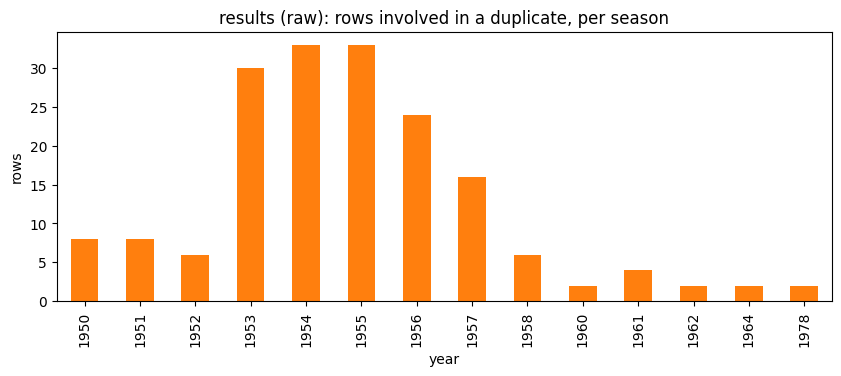

number of started rows per duplicated pair:


grid
2    76
3     6
0     3
Name: count, dtype: int64

In [263]:
years = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId", "year"])
dup_plot = dup_rows.merge(years, on="raceId", how="left")     # copy for plotting only

dup_plot.groupby("year").size().plot(kind="bar", color="tab:orange", figsize=(10, 3.5),
                                     title="results (raw): rows involved in a duplicate, per season")
plt.ylabel("rows")
plt.show()

# In how many duplicated pairs did exactly one of the rows start from a real grid slot (grid > 0)?
started_per_pair = dup_rows.groupby(["raceId", "driverId"])["grid"].apply(lambda g: (g > 0).sum())
print("number of started rows per duplicated pair:")
started_per_pair.value_counts()

In [264]:
results_clean = (results_clean
                 .sort_values(["raceId", "driverId", "positionOrder", "resultId"])
                 .drop_duplicates(["raceId", "driverId"], keep="first")
                 .sort_values("resultId")
                 .reset_index(drop=True))

print("rows after:", len(results_clean), "| removed:", len(results) - len(results_clean))

rows after: 26668 | removed: 91


In [265]:
assert not results_clean.duplicated(["raceId", "driverId"]).any()
print("OK: (raceId, driverId) is unique")

OK: (raceId, driverId) is unique


In [266]:
# table with ALL rows, duplicates included (same load as the cleaning cell)
results_with_dups = pd.read_csv(DATA_DIR / "results.csv", keep_default_na=False, na_values=[r"\N"])

old_rule = (results_with_dups.sort_values(["raceId", "driverId", "resultId"])
                             .drop_duplicates(["raceId", "driverId"], keep="first")
                             .set_index(["raceId", "driverId"])["positionOrder"])
new_rule = results_clean.set_index(["raceId", "driverId"])["positionOrder"]

pair_index = (results_with_dups[results_with_dups.duplicated(["raceId", "driverId"], keep=False)]
              .set_index(["raceId", "driverId"]).index.unique())
cmp = pd.DataFrame({"lowest_resultId": old_rule.loc[pair_index], "best_positionOrder": new_rule.loc[pair_index]})

print("duplicated pairs:", len(cmp))
print("podium labels that differ between the two rules:",
      int(((cmp["lowest_resultId"] <= 3) != (cmp["best_positionOrder"] <= 3)).sum()))
print("podium rate in these pairs - lowest resultId:", round((cmp["lowest_resultId"] <= 3).mean(), 3),
      "| best positionOrder:", round((cmp["best_positionOrder"] <= 3).mean(), 3))

duplicated pairs: 85
podium labels that differ between the two rules: 16
podium rate in these pairs - lowest resultId: 0.071 | best positionOrder: 0.259


In [267]:
podium_per_race = (results_clean["positionOrder"] <= 3).groupby(results_clean["raceId"]).sum()
print(podium_per_race.value_counts())
print("races with != 3 podium rows:", int((podium_per_race != 3).sum()))

positionOrder
3    1107
4      16
5       2
Name: count, dtype: int64
races with != 3 podium rows: 18


In [268]:
print("resultId unique  :", results_clean["resultId"].is_unique)
print("resultId no nulls:", results_clean["resultId"].notna().all())

resultId unique  : True
resultId no nulls: True


In [269]:
races_ids        = pd.read_csv(DATA_DIR / "races.csv", usecols=["raceId"])["raceId"]
drivers_ids      = pd.read_csv(DATA_DIR / "drivers.csv", usecols=["driverId"])["driverId"]
constructors_ids = pd.read_csv(DATA_DIR / "constructors.csv", usecols=["constructorId"])["constructorId"]
status_ids       = pd.read_csv(DATA_DIR / "status.csv", usecols=["statusId"])["statusId"]

rows = []
for col, parent, ids in [("raceId", "races.raceId", races_ids),
                         ("driverId", "drivers.driverId", drivers_ids),
                         ("constructorId", "constructors.constructorId", constructors_ids),
                         ("statusId", "status.statusId", status_ids)]:
    orphans = int((~results_clean[col].dropna().isin(ids)).sum())
    rows.append({"foreign key": f"results.{col}", "points to": parent,
                 "null values": int(results_clean[col].isna().sum()),
                 "orphan rows": orphans, "ok": orphans == 0})
pd.DataFrame(rows)

,foreign key,points to,null values,orphan rows,ok
0,results.raceId,races.raceId,0,0,True
1,results.driverId,drivers.driverId,0,0,True
2,results.constructorId,constructors.constructorId,0,0,True
3,results.statusId,status.statusId,0,0,True


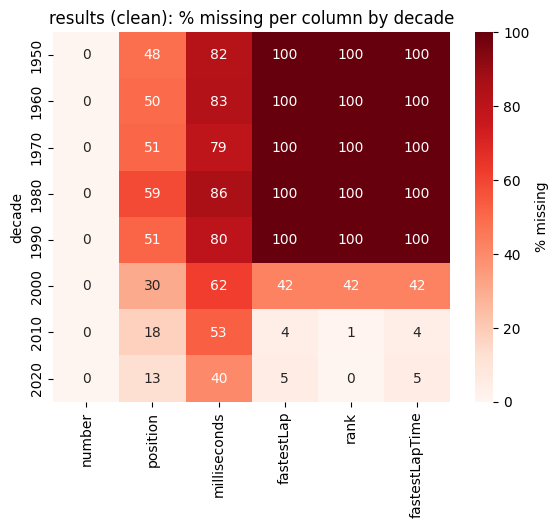

In [270]:
import seaborn as sns

res_year = results_clean.merge(years, on="raceId", how="left")     # copy for plotting only
cols = ["number", "position", "milliseconds", "fastestLap", "rank", "fastestLapTime"]
miss_dec = (res_year.assign(decade=(res_year["year"] // 10) * 10)
                    .groupby("decade")[cols]
                    .apply(lambda d: d.isna().mean() * 100))

sns.heatmap(miss_dec, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% missing"})
plt.title("results (clean): % missing per column by decade")
plt.show()

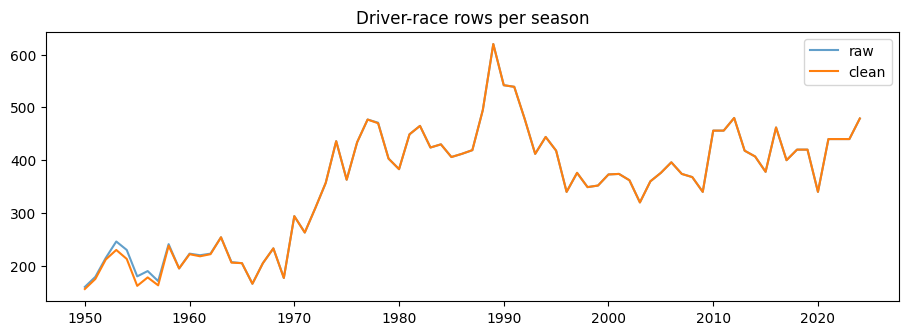

In [271]:
before_rows = pd.read_csv(DATA_DIR / "results.csv", usecols=["raceId"]).merge(years, on="raceId").groupby("year").size()
after_rows  = res_year.groupby("year").size()

plt.figure(figsize=(11, 3.5))
plt.plot(before_rows.index, before_rows.values, label="raw", alpha=0.7)
plt.plot(after_rows.index, after_rows.values, label="clean")
plt.title("Driver-race rows per season")
plt.legend()
plt.show()

In [272]:
pd.DataFrame({
    "rows": [len(results), len(results_clean)],
    "columns": [results.shape[1], results_clean.shape[1]],
    "missing values": [int(before_res["sentinel (\\N)"].sum()), int(results_clean.isnull().sum().sum())],
    "text '\\N' left": [int(before_res["sentinel (\\N)"].sum()), 0],
    "duplicate (raceId, driverId)": [n_dup, 0],
}, index=["before", "after"])

,rows,columns,missing values,text '\N' left,"duplicate (raceId, driverId)"
before,26759,18,122887,122887,91
after,26668,19,140676,0,0


### Duplicate-result handling rule

The retained implementation prefers a row with `grid > 0`, then the smallest `resultId`. This is a deterministic selection rule, not a reliable definition of whether a driver started: zero grid can represent special starts or other historical cases. The flag is used only for duplicate selection and removed afterward. The original `results` table preserves all records; assess the effect on labels and historical shared drives before finalizing the modeling table.


# Hamza — seasons, sprint results, status


**seasons.csv**

In [273]:
seasons_clean = pd.read_csv(DATA_DIR / "seasons.csv",na_values=[r"\N"]) 

In [274]:
seasons_clean.head()

,year,url
0,2009,http://en.wikipedia.org/wiki/2009_Formula_One_...
1,2008,http://en.wikipedia.org/wiki/2008_Formula_One_...
2,2007,http://en.wikipedia.org/wiki/2007_Formula_One_...
3,2006,http://en.wikipedia.org/wiki/2006_Formula_One_...
4,2005,http://en.wikipedia.org/wiki/2005_Formula_One_...


In [275]:
seasons_clean.isnull().sum()

year    0
url     0
dtype: int64

**sprint_results.csv**

In [276]:
sprint_results_clean =  pd.read_csv(DATA_DIR / "sprint_results.csv",na_values=[r"\N"])


In [277]:
sprint_results.isnull().sum()

resultId          0
raceId            0
driverId          0
constructorId     0
number            0
grid              0
position          0
positionText      0
positionOrder     0
points            0
laps              0
time              0
milliseconds      0
fastestLap        0
fastestLapTime    0
statusId          0
dtype: int64

In [278]:
sprint_results_clean.isnull().sum()

resultId           0
raceId             0
driverId           0
constructorId      0
number             0
grid               0
position          15
positionText       0
positionOrder      0
points             0
laps               0
time              20
milliseconds      20
fastestLap         9
fastestLapTime     9
statusId           0
dtype: int64

In [279]:
sprint_results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   resultId        360 non-null    int64  
 1   raceId          360 non-null    int64  
 2   driverId        360 non-null    int64  
 3   constructorId   360 non-null    int64  
 4   number          360 non-null    int64  
 5   grid            360 non-null    int64  
 6   position        345 non-null    float64
 7   positionText    360 non-null    object 
 8   positionOrder   360 non-null    int64  
 9   points          360 non-null    int64  
 10  laps            360 non-null    int64  
 11  time            340 non-null    object 
 12  milliseconds    340 non-null    float64
 13  fastestLap      351 non-null    float64
 14  fastestLapTime  351 non-null    object 
 15  statusId        360 non-null    int64  
dtypes: float64(3), int64(10), object(3)
memory usage: 45.1+ KB


In [280]:
sprint_results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1,1,1,3,17,25:38.426,1538426,14,1:30.013,1
1,2,1061,1,131,44,1,2,2,2,2,17,+1.430,1539856,17,1:29.937,1
2,3,1061,822,131,77,3,3,3,3,1,17,+7.502,1545928,17,1:29.958,1
3,4,1061,844,6,16,4,4,4,4,0,17,+11.278,1549704,16,1:30.163,1
4,5,1061,846,1,4,6,5,5,5,0,17,+24.111,1562537,16,1:30.566,1


In [281]:
sprint_results_clean.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId
0,1,1061,830,9,33,2,1.0,1,1,3,17,25:38.426,1538426.0,14.0,1:30.013,1
1,2,1061,1,131,44,1,2.0,2,2,2,17,+1.430,1539856.0,17.0,1:29.937,1
2,3,1061,822,131,77,3,3.0,3,3,1,17,+7.502,1545928.0,17.0,1:29.958,1
3,4,1061,844,6,16,4,4.0,4,4,0,17,+11.278,1549704.0,16.0,1:30.163,1
4,5,1061,846,1,4,6,5.0,5,5,0,17,+24.111,1562537.0,16.0,1:30.566,1


In [282]:
def time_to_seconds(x):
    if pd.isna(x):
        return np.nan
    parts = str(x).strip().lstrip("+").split(":")
    if not 1 <= len(parts) <= 3:
        raise ValueError(f"Unexpected duration: {x}")
    values = [float(part) for part in parts]
    if not all(np.isfinite(v) and v >= 0 for v in values) or any(v >= 60 for v in values[1:]):
        raise ValueError(f"Invalid duration: {x}")
    seconds = 0.0
    for value in values:
        seconds = seconds * 60 + value
    return seconds


In [283]:
# Preserve original strings. Total times and gaps have different meanings.
sprint_time_text = sprint_results_clean["time"].astype("string").str.strip()
sprint_is_gap = sprint_time_text.str.startswith("+", na=False)
sprint_results_clean["race_total_seconds_from_text"] = pd.to_numeric(
    sprint_time_text.where(~sprint_is_gap).map(time_to_seconds), errors="raise")
sprint_results_clean["gap_to_winner_seconds"] = pd.to_numeric(
    sprint_time_text.where(sprint_is_gap).str.removeprefix("+").map(time_to_seconds), errors="raise")
display(sprint_results_clean[["time", "race_total_seconds_from_text", "gap_to_winner_seconds"]].head(10))


,time,race_total_seconds_from_text,gap_to_winner_seconds
0,25:38.426,1538.426,NaN
1,+1.430,NaN,1.430
2,+7.502,NaN,7.502
3,+11.278,NaN,11.278
4,+24.111,NaN,24.111
5,+30.959,NaN,30.959
6,+43.527,NaN,43.527
7,+44.439,NaN,44.439
8,+46.652,NaN,46.652
9,+47.395,NaN,47.395


In [284]:
sprint_results_clean["fastestLapTime_sec"] = pd.to_numeric(
    sprint_results_clean["fastestLapTime"].map(time_to_seconds), errors="raise")
display(sprint_results_clean[["fastestLapTime", "fastestLapTime_sec"]].head(10))


,fastestLapTime,fastestLapTime_sec
0,1:30.013,90.013
1,1:29.937,89.937
2,1:29.958,89.958
3,1:30.163,90.163
4,1:30.566,90.566
5,1:30.640,90.640
6,1:31.773,91.773
7,1:31.687,91.687
8,1:32.208,92.208
9,1:32.183,92.183


In [285]:
# Verify each populated source value parsed; do not repeat conversions.
parsed_sprint_time = sprint_results_clean["race_total_seconds_from_text"].where(
    ~sprint_is_gap, sprint_results_clean["gap_to_winner_seconds"])
assert not (sprint_results_clean["time"].notna() & parsed_sprint_time.isna()).any()
assert not (sprint_results_clean["fastestLapTime"].notna() & sprint_results_clean["fastestLapTime_sec"].isna()).any()
print("Sprint time and fastestLapTime converted without losing populated values.")


Sprint time and fastestLapTime converted without losing populated values.


In [286]:
sprint_results_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   resultId                      360 non-null    int64  
 1   raceId                        360 non-null    int64  
 2   driverId                      360 non-null    int64  
 3   constructorId                 360 non-null    int64  
 4   number                        360 non-null    int64  
 5   grid                          360 non-null    int64  
 6   position                      345 non-null    float64
 7   positionText                  360 non-null    object 
 8   positionOrder                 360 non-null    int64  
 9   points                        360 non-null    int64  
 10  laps                          360 non-null    int64  
 11  time                          340 non-null    object 
 12  milliseconds                  340 non-null    float64
 13  faste

In [287]:
sprint_results_clean.duplicated(
    subset=["raceId", "driverId"]
).sum()

np.int64(0)

In [288]:
duplicates = sprint_results_clean[
    sprint_results_clean.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
]

duplicates

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,fastestLapTime,statusId,race_total_seconds_from_text,gap_to_winner_seconds,fastestLapTime_sec


**status.csv**

In [289]:
status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   statusId  139 non-null    int64 
 1   status    139 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.3+ KB


In [290]:
status_clean = pd.read_csv(DATA_DIR / "status.csv",na_values=[r"\N"]) 

In [291]:
status.isnull().sum()

statusId    0
status      0
dtype: int64

In [292]:
status.duplicated(subset=["statusId"]).sum()

np.int64(0)

### Remaining audit work

The supplied Hamza section ends here without a full three-table uniqueness/reference audit. This merge preserves the supplied inspections; it does not claim Objective 1 is complete for all tables. Add missing key checks, references, and before/after evidence before submission.


# PART 2 Data engineering questions

# QUESTION 1 

In [293]:
circuits_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   circuitId   77 non-null     int64  
 1   circuitRef  77 non-null     object 
 2   name        77 non-null     object 
 3   location    77 non-null     object 
 4   country     77 non-null     object 
 5   lat         77 non-null     float64
 6   lng         77 non-null     float64
 7   alt         77 non-null     int64  
 8   url         77 non-null     object 
dtypes: float64(2), int64(2), object(5)
memory usage: 5.5+ KB


In [294]:
races_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1125 entries, 0 to 1124
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype          
---  ------           --------------  -----          
 0   raceId           1125 non-null   int64          
 1   year             1125 non-null   int64          
 2   round            1125 non-null   int64          
 3   circuitId        1125 non-null   int64          
 4   name             1125 non-null   object         
 5   date             1125 non-null   datetime64[ns] 
 6   time             394 non-null    object         
 7   url              1125 non-null   object         
 8   fp1_date         90 non-null     datetime64[ns] 
 9   fp1_time         68 non-null     object         
 10  fp2_date         90 non-null     datetime64[ns] 
 11  fp2_time         68 non-null     object         
 12  fp3_date         72 non-null     datetime64[ns] 
 13  fp3_time         53 non-null     object         
 14  quali_date       90 non-

In [295]:
# Select the columns needed for Question 1.
q1_results = results_clean[
    ["raceId", "driverId", "grid", "positionOrder"]
]
q1_races = races_clean[["raceId", "circuitId", "year"]]
q1_circuits = circuits_clean[["circuitId", "name"]]

# Add the circuit ID and year to each driver–race record.
q1 = q1_results.merge(q1_races, on="raceId", how="left")

# Add the circuit name.
q1 = q1.merge(q1_circuits, on="circuitId", how="left")
q1 = q1.rename(columns={"name": "circuit_name"})

q1.head()

,raceId,driverId,grid,positionOrder,circuitId,year,circuit_name
0,18,1,1,1,1,2008,Albert Park Grand Prix Circuit
1,18,2,5,2,1,2008,Albert Park Grand Prix Circuit
2,18,3,7,3,1,2008,Albert Park Grand Prix Circuit
3,18,4,11,4,1,2008,Albert Park Grand Prix Circuit
4,18,5,3,5,1,2008,Albert Park Grand Prix Circuit


In [296]:
assert not q1.duplicated(["raceId", "driverId"]).any()

In [297]:
front_row = q1[q1["grid"].isin([1, 2])].copy()

In [298]:
front_row["podium"] = front_row["positionOrder"] <= 3

In [299]:
front_row["period"] = "Before 2014"

front_row.loc[
    front_row["year"] >= 2014, "period"
] = "2014 onward"

In [300]:
race_summary = (
    front_row.groupby(["raceId", "circuitId", "circuit_name", "period"])
    .agg(
        front_row_drivers=("driverId", "size"),
        podium_drivers=("podium", "sum")
    )
    .reset_index()
)

# Keep races with both front-row driver records.
race_summary = race_summary[
    race_summary["front_row_drivers"] == 2
].copy()

race_summary["both_on_podium"] = (
    race_summary["podium_drivers"] == 2
)

In [301]:
q1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   raceId         26668 non-null  int64 
 1   driverId       26668 non-null  int64 
 2   grid           26668 non-null  int64 
 3   positionOrder  26668 non-null  int64 
 4   circuitId      26668 non-null  int64 
 5   year           26668 non-null  int64 
 6   circuit_name   26668 non-null  object
dtypes: int64(6), object(1)
memory usage: 1.4+ MB


In [302]:
q1["raceId"].nunique()

1125

In [304]:
q1

,raceId,driverId,grid,positionOrder,circuitId,year,circuit_name
0,18,1,1,1,1,2008,Albert Park Grand Prix Circuit
1,18,2,5,2,1,2008,Albert Park Grand Prix Circuit
2,18,3,7,3,1,2008,Albert Park Grand Prix Circuit
3,18,4,11,4,1,2008,Albert Park Grand Prix Circuit
4,18,5,3,5,1,2008,Albert Park Grand Prix Circuit
...,...,...,...,...,...,...,...
26663,1144,825,14,16,24,2024,Yas Marina Circuit
26664,1144,859,12,17,24,2024,Yas Marina Circuit
26665,1144,822,9,18,24,2024,Yas Marina Circuit
26666,1144,861,20,19,24,2024,Yas Marina Circuit


In [305]:
circuit_counts = (
    race_summary.groupby(["circuitId", "circuit_name", "period"])
    .agg(
        successful_races=("both_on_podium", "sum"),
        eligible_races=("raceId", "size")
    )
    .reset_index()
)

circuit_counts = circuit_counts.sort_values(
    ["period", "successful_races"],
    ascending=[True, False]
)

display(circuit_counts)

,circuitId,circuit_name,period,successful_races,eligible_races
6,4,Circuit de Barcelona-Catalunya,2014 onward,8,11
40,24,Yas Marina Circuit,2014 onward,8,11
91,70,Red Bull Ring,2014 onward,8,13
10,6,Circuit de Monaco,2014 onward,7,10
15,9,Silverstone Circuit,2014 onward,7,12
...,...,...,...,...,...
80,60,Riverside International Raceway,Before 2014,0,1
81,61,AVUS,Before 2014,0,1
82,62,Monsanto Park Circuit,Before 2014,0,1
83,63,Sebring International Raceway,Before 2014,0,1


In [306]:
circuit_counts.eligible_races.sum()

np.int64(1103)

In [307]:
print("All races:", q1["raceId"].nunique())

print(
    "Races with at least one front-row record:",
    front_row["raceId"].nunique()
)

print(
    "Races with both front-row records:",
    race_summary["raceId"].nunique()
)

All races: 1125
Races with at least one front-row record: 1124
Races with both front-row records: 1103


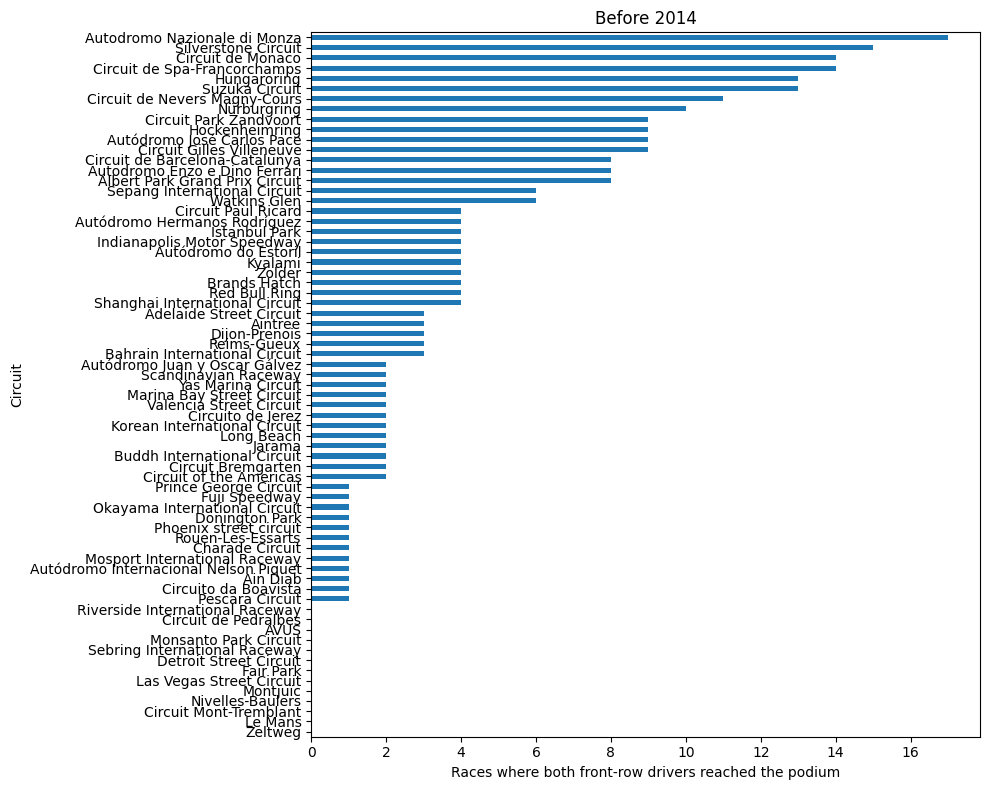

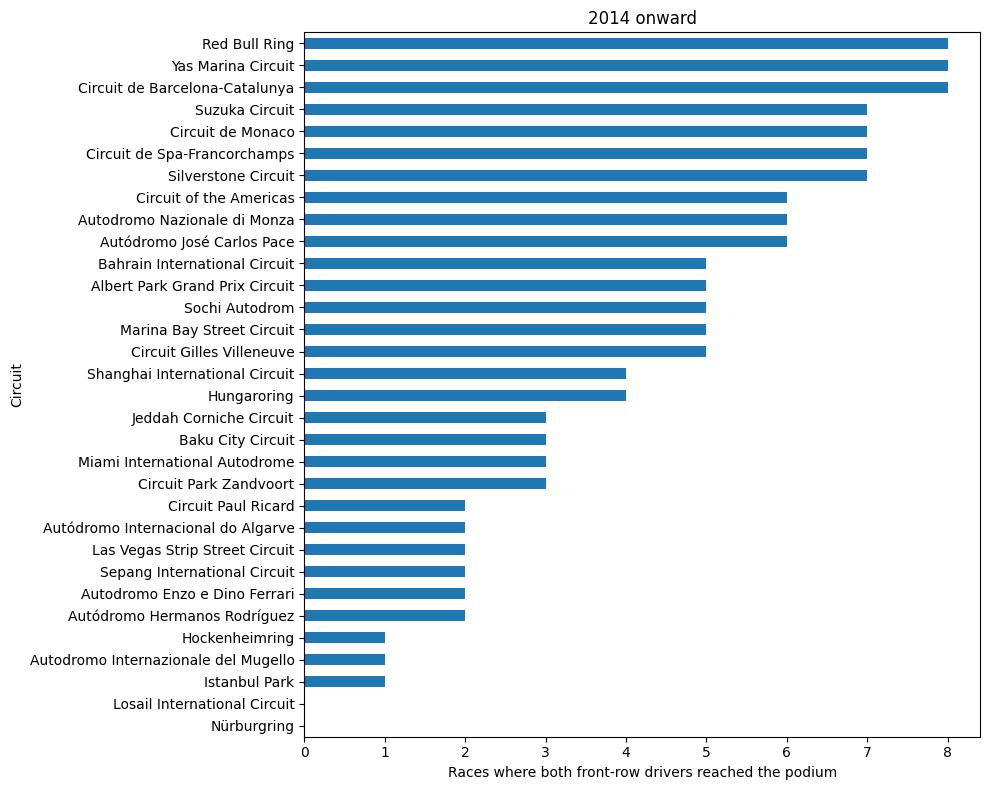

In [308]:
for period in ["Before 2014", "2014 onward"]:
    counts = circuit_counts[
        circuit_counts["period"] == period
    ].sort_values("successful_races")

    counts.plot.barh(
        x="circuit_name",
        y="successful_races",
        figsize=(10, 8),
        legend=False
    )

    plt.xlabel("Races where both front-row drivers reached the podium")
    plt.ylabel("Circuit")
    plt.title(period)
    plt.tight_layout()
    plt.show()

# QUESTION 2 

In [310]:
q2_results = results_clean[["raceId", "driverId", "grid", "positionOrder"]]
q2_races = races_clean[["raceId", "circuitId", "year"]]
q2_circuits = circuits_clean[["circuitId", "country"]]
q2_drivers = drivers_clean[["driverId", "nationality"]]

In [312]:
q2 = q2_results.merge(q2_races, on="raceId", how="left")
q2 = q2.merge(q2_circuits, on="circuitId", how="left")
q2 = q2.merge(q2_drivers, on="driverId", how="left")
q2 = q2.rename(columns={"country": "circuit_country",
                        "nationality": "driver_nationality"})

q2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   raceId              26668 non-null  int64 
 1   driverId            26668 non-null  int64 
 2   grid                26668 non-null  int64 
 3   positionOrder       26668 non-null  int64 
 4   circuitId           26668 non-null  int64 
 5   year                26668 non-null  int64 
 6   circuit_country     26668 non-null  object
 7   driver_nationality  26668 non-null  object
dtypes: int64(6), object(2)
memory usage: 1.6+ MB


In [313]:
print(sorted(q2["driver_nationality"].dropna().unique()))
print(sorted(q2["circuit_country"].dropna().unique()))

['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'United States']


In [314]:
# Each nationality maps to the circuit-country spelling(s) used in circuits.csv.
nat_to_countries = {
    "American": {"United States"},
    "American-Italian": {"United States", "Italy"},
    "Argentine": {"Argentina"},
    "Argentine-Italian": {"Argentina", "Italy"},
    "Australian": {"Australia"},
    "Austrian": {"Austria"},
    "Belgian": {"Belgium"},
    "Brazilian": {"Brazil"},
    "British": {"UK"},
    "Canadian": {"Canada"},
    "Chinese": {"China"},
    "Dutch": {"Netherlands"},
    "French": {"France"},
    "German": {"Germany"},
    "Hungarian": {"Hungary"},
    "Indian": {"India"},
    "Italian": {"Italy"},
    "Japanese": {"Japan"},
    "Malaysian": {"Malaysia"},
    "Mexican": {"Mexico"},
    "Monegasque": {"Monaco"},
    "Portuguese": {"Portugal"},
    "Russian": {"Russia"},
    "South African": {"South Africa"},
    "Spanish": {"Spain"},
    "Swedish": {"Sweden"},
    "Swiss": {"Switzerland"},
}

q2["home_countries"] = q2["driver_nationality"].map(nat_to_countries)

# True if the driver's nationality has at least one circuit in the dataset.
q2["has_home_circuit"] = q2["home_countries"].notna()

# 1 = driver races in their own country, 0 = anywhere else.
q2["is_home"] = [
    int(isinstance(home, set) and country in home)
    for home, country in zip(q2["home_countries"], q2["circuit_country"])
]

# Nationalities with no home circuit in the data (always "away" by construction).
print(q2.loc[~q2["has_home_circuit"], "driver_nationality"].value_counts())

# Sanity check: home starts per nationality. Every mapped nationality should have some.
print(q2.loc[q2["is_home"] == 1, "driver_nationality"].value_counts())

driver_nationality
Finnish            1193
New Zealander       407
Danish              221
Colombian           125
Thai                124
Venezuelan          120
Polish               99
Irish                92
Chilean              37
Rhodesian            18
Liechtensteiner      13
Indonesian           12
Uruguayan             7
East German           5
Czech                 3
Name: count, dtype: int64
driver_nationality
American             500
British              482
Italian              463
French               218
German               208
Brazilian            119
Belgian               66
Spanish               65
South African         59
Japanese              56
Argentine             45
Canadian              34
Austrian              31
Dutch                 28
Australian            28
Mexican               24
Swiss                 13
Swedish               13
Monegasque            13
Russian                8
Portuguese             6
Hungarian              2
Indian                 2
A

In [315]:
q2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26668 entries, 0 to 26667
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   raceId              26668 non-null  int64 
 1   driverId            26668 non-null  int64 
 2   grid                26668 non-null  int64 
 3   positionOrder       26668 non-null  int64 
 4   circuitId           26668 non-null  int64 
 5   year                26668 non-null  int64 
 6   circuit_country     26668 non-null  object
 7   driver_nationality  26668 non-null  object
 8   home_countries      24192 non-null  object
 9   has_home_circuit    26668 non-null  bool  
 10  is_home             26668 non-null  int64 
dtypes: bool(1), int64(7), object(3)
memory usage: 2.1+ MB


In [316]:
q2["podium"] = (q2["positionOrder"] <= 3).astype(int)

In [317]:
q2

,raceId,driverId,grid,positionOrder,circuitId,year,circuit_country,driver_nationality,home_countries,has_home_circuit,is_home,podium
0,18,1,1,1,1,2008,Australia,British,{UK},True,0,1
1,18,2,5,2,1,2008,Australia,German,{Germany},True,0,1
2,18,3,7,3,1,2008,Australia,German,{Germany},True,0,1
3,18,4,11,4,1,2008,Australia,Spanish,{Spain},True,0,0
4,18,5,3,5,1,2008,Australia,Finnish,NaN,False,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
26663,1144,825,14,16,24,2024,UAE,Danish,NaN,False,0,0
26664,1144,859,12,17,24,2024,UAE,New Zealander,NaN,False,0,0
26665,1144,822,9,18,24,2024,UAE,Finnish,NaN,False,0,0
26666,1144,861,20,19,24,2024,UAE,Argentine,{Argentina},True,0,0


In [318]:
print("grid == 0 rows:", (q2["grid"] == 0).sum(), "| missing grid:", q2["grid"].isna().sum())
q2 = q2[q2["grid"] > 0].copy()

grid == 0 rows: 1635 | missing grid: 0


In [320]:
q2["grid_bin"] = pd.cut(
    q2["grid"],
    bins=[0, 2, 4, 6, 10, 15, 40],
    labels=["1-2", "3-4", "5-6", "7-10", "11-15", "16+"],
)

In [321]:
# Uncontrolled: simple home vs away podium rate.
overall = q2.groupby("is_home")["podium"].agg(starts="size", podiums="sum", rate="mean")
print(overall)

# Controlled: home vs away podium rate within each grid bin.
by_bin = (
    q2.groupby(["grid_bin", "is_home"], observed=True)["podium"]
    .agg(starts="size", rate="mean")
    .unstack("is_home")
)
by_bin

         starts  podiums      rate
is_home                           
0         22714     3129  0.137756
1          2319      266  0.114705


starts           rate          
is_home       0    1         0         1
grid_bin                                
1-2        2064  179  0.604651  0.553073
3-4        2085  170  0.400959  0.429412
5-6        2065  176  0.219370  0.210227
7-10       4123  388  0.093379  0.087629
11-15      5135  470  0.029990  0.034043
16+        7242  936  0.007318  0.007479

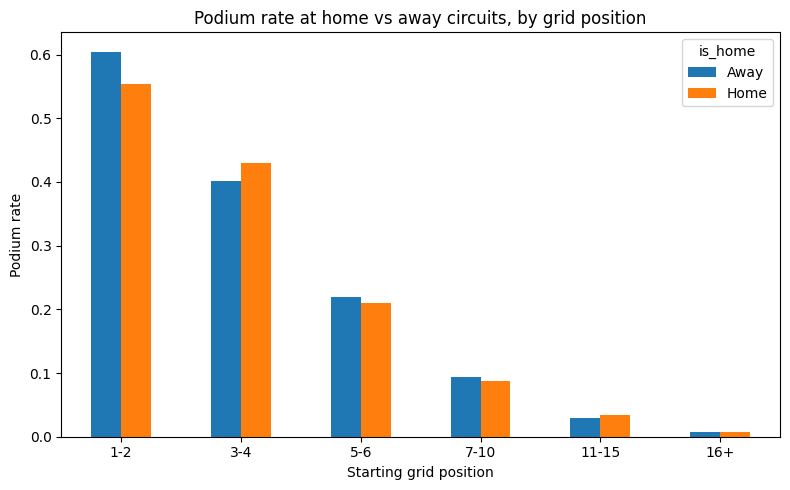

In [322]:
import matplotlib.pyplot as plt

rate = by_bin["rate"].rename(columns={0: "Away", 1: "Home"})
ax = rate.plot(kind="bar", figsize=(8, 5))
ax.set_xlabel("Starting grid position")
ax.set_ylabel("Podium rate")
ax.set_title("Podium rate at home vs away circuits, by grid position")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Question 3

In [323]:
q3_results = results_clean[["raceId", "driverId", "constructorId", "statusId"]]
q3_races = races_clean[["raceId", "year"]]
q3_constructors = constructors_clean[["constructorId", "name"]]
q3_status = status_clean[["statusId", "status"]]

# Add the season to each driver–race record.
q3 = q3_results.merge(q3_races, on="raceId", how="left")

# Add the constructor name and the status text.
q3 = q3.merge(q3_constructors, on="constructorId", how="left")
q3 = q3.merge(q3_status, on="statusId", how="left")
q3 = q3.rename(columns={"name": "constructor_name"})

q3.head()

,raceId,driverId,constructorId,statusId,year,constructor_name,status
0,18,1,1,1,2008,McLaren,Finished
1,18,2,2,1,2008,BMW Sauber,Finished
2,18,3,3,1,2008,Williams,Finished
3,18,4,4,1,2008,Renault,Finished
4,18,5,1,1,2008,McLaren,Finished


In [324]:
# Keep only the two periods being compared.
q3 = q3[q3["year"].between(2014, 2024)].copy()
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")

print(q3.groupby("period")["raceId"].nunique())
print("Missing status:", q3["status"].isna().sum())

period
2014-2021    160
2022-2024     68
Name: raceId, dtype: int64
Missing status: 0


In [325]:
# Review these before deciding what counts as mechanical.
print(q3["status"].value_counts().to_string())

status
Finished            2403
+1 Lap              1178
+2 Laps              208
Collision            150
Accident              85
Engine                81
Collision damage      59
Retired               50
Brakes                49
Power Unit            42
Gearbox               42
Suspension            25
+3 Laps               24
Hydraulics            15
Withdrew              14
Electrical            14
Power loss            13
Wheel                 11
Spun off              11
Disqualified          11
Oil leak              10
Overheating            8
Water pressure         7
Puncture               7
Mechanical             7
Turbo                  6
+4 Laps                6
Exhaust                5
Fuel pressure          5
Battery                5
ERS                    5
Tyre                   4
Electronics            4
Water leak             4
Undertray              4
Front wing             3
Radiator               3
Wheel nut              3
Illness                3
Transmission      

In [326]:
from scipy.stats import spearmanr

MIN_STARTS = 40   # same threshold as Cell 5

# Main definition: a car component failed, with no sign of contact or a decision.
mechanical_statuses = {
    "engine", "brakes", "power unit", "gearbox", "suspension", "hydraulics",
    "electrical", "power loss", "oil leak", "overheating", "water pressure",
    "mechanical", "turbo", "exhaust", "fuel pressure", "battery", "ers",
    "electronics", "water leak", "radiator", "transmission", "oil pressure",
    "steering", "fuel leak", "clutch", "technical", "vibrations", "throttle",
    "driveshaft", "fuel system", "drivetrain", "brake duct", "spark plugs",
    "cooling system", "water pump", "fuel pump", "differential",
}

# Borderline: ambiguous cause, used only for the sensitivity check.
borderline_statuses = {"wheel", "wheel nut", "tyre", "puncture", "undertray", "seat", "retired"}

q3["status_lc"] = q3["status"].str.lower().str.strip()
q3["is_mechanical"] = q3["status_lc"].isin(mechanical_statuses).astype(int)
q3["is_mechanical_broad"] = q3["status_lc"].isin(mechanical_statuses | borderline_statuses).astype(int)

print("Mechanical retirements (main):", q3["is_mechanical"].sum())
print("Mechanical retirements (broad):", q3["is_mechanical_broad"].sum())

# Documentation: everything that is NOT finished and NOT counted as mechanical.
finished = (q3["status_lc"] == "finished") | q3["status_lc"].str.startswith("+", na=False)
print(q3.loc[(q3["is_mechanical"] == 0) & ~finished, "status"].value_counts().to_string())

# Sensitivity: does the constructor ranking change if borderline cases are included?
def rate_table(flag):
    r = (q3.groupby(["period", "constructor_name"])
           .agg(starts=(flag, "size"), n=(flag, "sum")).reset_index())
    r["rate"] = r["n"] / r["starts"]
    return r[r["starts"] >= MIN_STARTS]

cmp = rate_table("is_mechanical").merge(
    rate_table("is_mechanical_broad"),
    on=["period", "constructor_name"], suffixes=("_main", "_broad"))

for period, g in cmp.groupby("period"):
    rho, _ = spearmanr(g["rate_main"], g["rate_broad"])
    print(f"{period}: rank correlation main vs broad = {rho:.2f}")

Mechanical retirements (main): 377
Mechanical retirements (broad): 457
status
Collision           150
Accident             85
Collision damage     59
Retired              50
Withdrew             14
Disqualified         11
Wheel                11
Spun off             11
Puncture              7
Tyre                  4
Undertray             4
Rear wing             3
Illness               3
Front wing            3
Wheel nut             3
Damage                2
Excluded              1
Seat                  1
Debris                1
Out of fuel           1
2014-2021: rank correlation main vs broad = 0.97
2022-2024: rank correlation main vs broad = 0.67


In [327]:
# Grain: one row = one car starting one race. Rate = mechanical retirements / starts.
rates = (
    q3.groupby(["period", "constructor_name"])
    .agg(starts=("is_mechanical", "size"), mech_retirements=("is_mechanical", "sum"))
    .reset_index()
)
rates["mech_rate"] = rates["mech_retirements"] / rates["starts"]
rates = rates[rates["starts"] >= MIN_STARTS]

# Ranking in each period.
for period in ["2014-2021", "2022-2024"]:
    print(f"\n=== {period} ===")
    print(rates[rates["period"] == period]
          .sort_values("mech_rate", ascending=False)
          .round(3).to_string(index=False))

# Side by side (constructors present in both periods).
wide = rates.pivot(index="constructor_name", columns="period", values="mech_rate").dropna()
wide["change"] = wide["2022-2024"] - wide["2014-2021"]
wide.sort_values("2014-2021", ascending=False).round(3)


=== 2014-2021 ===
   period constructor_name  starts  mech_retirements  mech_rate
2014-2021         Lotus F1      76                13      0.171
2014-2021       Toro Rosso     242                39      0.161
2014-2021          McLaren     320                44      0.138
2014-2021          Renault     200                27      0.135
2014-2021           Sauber     200                22      0.110
2014-2021         Red Bull     320                34      0.106
2014-2021       AlphaTauri      78                 8      0.103
2014-2021     Racing Point      76                 7      0.092
2014-2021     Haas F1 Team     244                18      0.074
2014-2021         Williams     320                23      0.072
2014-2021   Alpine F1 Team      44                 3      0.068
2014-2021   Manor Marussia      78                 5      0.064
2014-2021      Force India     200                12      0.060
2014-2021          Ferrari     320                17      0.053
2014-2021         Mer

period,2014-2021,2022-2024,change
constructor_name,,,
McLaren,0.138,0.037,-0.101
Sauber,0.110,0.021,-0.089
Red Bull,0.106,0.037,-0.069
AlphaTauri,0.103,0.068,-0.034
Haas F1 Team,0.074,0.044,-0.030
Williams,0.072,0.052,-0.020
Alpine F1 Team,0.068,0.110,0.042
Ferrari,0.053,0.059,0.006
Mercedes,0.038,0.044,0.007


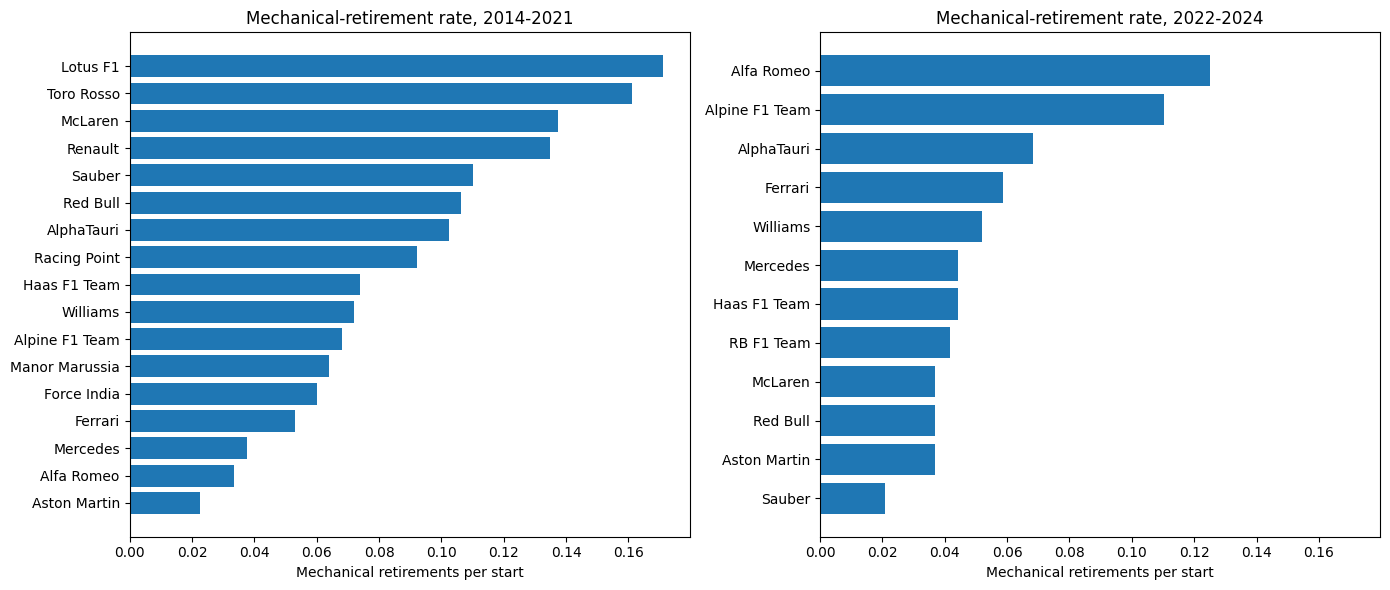

In [328]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, period in zip(axes, ["2014-2021", "2022-2024"]):
    d = (rates[rates["period"] == period]
         .sort_values("mech_rate", ascending=True))
    ax.barh(d["constructor_name"], d["mech_rate"])
    ax.set_title(f"Mechanical-retirement rate, {period}")
    ax.set_xlabel("Mechanical retirements per start")
plt.tight_layout()
plt.show()